# 05 · Penguatan data INATRADE tujuh komoditas: satu notebook dari awal sampai akhir

Dit. Bina Pasar Dalam Negeri (Binpas), Kemendag. Notebook ini merangkum seluruh pekerjaan penguatan data INATRADE
(sesi 12–14 Nov 2026) dan bisa dijalankan ulang dari atas ke bawah.

| Bagian | Isi | Jenis |
| --- | --- | --- |
| 1 | Tahap 0: profil data INATRADE | dihitung ulang dari file INATRADE + grafik pelapor |
| 2 | Validasi satuan daging sapi dan pupuk | dihitung ulang |
| 3 | Cakupan volume terhadap sumber BPS | tabel resmi ditampilkan (ambil ulang dari BPS opsional) |
| 4 | Lima komoditas yang diuji: resep, gerbang penyetelan, gerbang U1 resmi | tabel + log proses resmi + **replikasi** kalibrasi dan U1 + grafik |
| 5 | Keterwakilan beras (U2) terhadap Pola Distribusi BPS | tabel resmi + grafik + **replikasi** |
| 6 | Resep versi 2 (kedelai, daging kerbau, telur ayam ras) | tabel + log penyetelan resmi; **belum boleh diuji** |
| 7 | Ringkasan status tujuh komoditas | dari tabel resmi |
| 8 | (Opsional, mati) penyetelan ulang penuh | tidak dijalankan |

**Cara pakai di Google Colab:** unggah notebook ini dan `Non_PAW_dari_nol.xlsm` ke `MyDrive/inatrade_colab/`, buka
notebook, lalu *Runtime → Run all*. Perkiraan ±5–10 menit. Tidak perlu berkas lain: kode dan hasil resmi berukuran
kecil sudah tertanam di sel "Paket tertanam" dan diekstrak ke `inatrade_colab/paket/`. Semua keluaran notebook ada di
`inatrade_colab/hasil_ulang/`.

**Yang harus diingat saat membaca:**
- **Ujian akhir (U1) lima komoditas dan U2 beras sudah dijalankan sekali dan sudah terpakai.** Hasil resmi = berkas yang
  tercatat di repo (ditanam di notebook ini). Sel berlabel **REPLIKASI** menjalankan ulang langkah yang sama, dengan
  data, resep, dan kode yang sama, ke folder terpisah, hanya untuk menunjukkan bahwa angka resmi bisa diulang.
  Replikasi **bukan ujian baru** dan tidak mengubah status apa pun.
- Bila file INATRADE yang diunggah **berbeda** dari file hasil resmi (sha256 beda), itu data baru: sel replikasi
  dilewati otomatis. Data baru tidak boleh dipakai mengulang ujian yang sudah terpakai; ujian resep versi 2 punya
  aturan sendiri (bagian 6).
- Ambang lolos dikunci di `ambang_ujian.md` (11 Nov 2026) dan tidak diubah.
- **INTERNAL.** Keluaran di `hasil_ulang/` memuat data per perusahaan, dan kode tertanam memuat tiga kode perusahaan
  (daftar koreksi satuan). Jangan bagikan notebook atau folder ini di luar tim. Output yang tampil di notebook hanya
  angka agregat.

## 0. Persiapan
Tiga sel berikut: folder kerja dan file INATRADE, paket tertanam, lalu pustaka dan fungsi bantu.

In [1]:
import hashlib, json, os, shutil, subprocess, sys, time

DI_COLAB = 'google.colab' in sys.modules
if DI_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/inatrade_colab'   # <- ganti bila notebook + xlsm diunggah ke folder lain
else:
    BASE = os.path.abspath('.')                      # jalan lokal: folder kerja saat ini
assert os.path.isdir(BASE), f'folder tidak ditemukan: {BASE}'
os.chdir(BASE)

NAMA_XLSM = 'Non_PAW_dari_nol.xlsm'
XLSM = next((p for p in (NAMA_XLSM, os.path.join('data', 'inatrade', NAMA_XLSM)) if os.path.exists(p)), None)
assert XLSM, f'{NAMA_XLSM} tidak ditemukan di {BASE} (atau di {BASE}/data/inatrade)'

# File INATRADE yang dipakai semua hasil resmi (sesi 12-14 Nov 2026)
HASH_RESMI = 'c667dddba86bdfb624b441f7a10b5b29cd548cc9bd98fcbecd2c687faf5adac2'
with open(XLSM, 'rb') as f:
    HASH_XLSM = hashlib.sha256(f.read()).hexdigest()
DATA_SAMA = HASH_XLSM == HASH_RESMI

HASIL = 'hasil_ulang'            # semua keluaran notebook ini (di dalam BASE)
os.makedirs(HASIL, exist_ok=True)
print('folder kerja  :', BASE)
print('file INATRADE :', XLSM, '| sha256', HASH_XLSM[:16] + '...')
print('sama dengan file hasil resmi:', 'YA' if DATA_SAMA else 'TIDAK -> DATA BARU: sel replikasi U1/U2 dilewati')
print('CPU           :', os.cpu_count())

folder kerja  : /tmp/claude-0/-home-user-tess/fa35ddf3-bcbb-576e-a521-4413247ac474/scratchpad/MyDrive/inatrade_colab
file INATRADE : Non_PAW_dari_nol.xlsm | sha256 c667dddba86bdfb6...
sama dengan file hasil resmi: YA
CPU           : 4


In [2]:
#@title Paket tertanam: kode + hasil resmi berukuran kecil (sel panjang; cukup dijalankan)
import base64, io, tarfile

PAKET_B64 = """
...
AJgIAA==
"""

PAKET = os.path.join(BASE, 'paket')
shutil.rmtree(PAKET, ignore_errors=True)
_arsip = base64.b64decode(PAKET_B64)
with tarfile.open(fileobj=io.BytesIO(_arsip), mode='r:gz') as _tar:
    _n = len(_tar.getmembers())
    try:
        _tar.extractall(PAKET, filter='data')
    except TypeError:                # Python lama tanpa argumen filter
        _tar.extractall(PAKET)
print(f'paket diekstrak ke {os.path.relpath(PAKET, BASE)}/: {_n} berkas | sha256 arsip {hashlib.sha256(_arsip).hexdigest()[:16]}... '
      f'| kode pada commit 4e64932')

paket diekstrak ke paket/: 133 berkas | sha256 arsip 824dc9e06dea348f... | kode pada commit 4e64932


In [3]:
# --- pustaka untuk skrip (dijalankan sebagai proses terpisah) ---
PY = sys.executable
ENV = dict(os.environ)
PUSTAKA = None
if DI_COLAB:
    # Kode ditulis dan diuji dengan pandas 3.0.5. Supaya kernel Colab tidak terganggu (tanpa restart), pandas 3.0.5
    # dipasang ke folder terpisah dan hanya dipakai oleh skrip, yang dijalankan sebagai proses terpisah.
    PUSTAKA = '/content/pustaka_inatrade'
    if not os.path.isdir(os.path.join(PUSTAKA, 'pandas')):
        _r = subprocess.run([PY, '-m', 'pip', 'install', '-q', '--target', PUSTAKA, 'pandas==3.0.5', 'openpyxl'],
                            capture_output=True, text=True)
        if _r.returncode != 0:
            print('PERINGATAN: pandas 3.0.5 gagal dipasang; skrip memakai pandas bawaan (belum pernah diuji; angka '
                  'bisa berbeda dari hasil resmi).')
            print(_r.stderr[-1500:])
            shutil.rmtree(PUSTAKA, ignore_errors=True)
            PUSTAKA = None
    if PUSTAKA:
        ENV['PYTHONPATH'] = PUSTAKA + os.pathsep + ENV.get('PYTHONPATH', '')
# -u: output langsung tampil. Di luar Colab ditambah -I (mode terisolasi, seperti semua run resmi).
OPSI_PY = ['-u'] if PUSTAKA else ['-u', '-I']

# Skrip dijalankan lewat peluncur kecil yang memaksa cara "fork" untuk proses paralel (bawaan Python sampai 3.13;
# skrip mengandalkannya). Isi skrip tidak diubah.
_PELUNCUR = ("import multiprocessing as mp, runpy, sys\n"
             "mp.set_start_method('fork', force=True)\n"
             "sys.argv = sys.argv[1:]\n"
             "runpy.run_path(sys.argv[0], run_name='__main__')\n")


def samar(teks):
    """Kunci API BPS tidak pernah ikut tercetak."""
    k = ENV.get('BPS_API_KEY')
    return teks.replace(k, '***') if k else teks


def jalan(skrip, *argumen, tampil=True, log=None):
    """Jalankan skrip dari paket sebagai proses terpisah dan kembalikan kode keluarnya.
    tampil=False: hanya baris kepala run ("== ...") yang dicetak; seluruh output disimpan ke berkas `log`."""
    cmd = [PY, *OPSI_PY, '-c', _PELUNCUR, os.path.join(PAKET, skrip)] + [str(a) for a in argumen]
    t0, semua, kepala = time.time(), [], False
    p = subprocess.Popen(cmd, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for baris in p.stdout:
        baris = samar(baris)
        semua.append(baris)
        if tampil or (not kepala and baris.startswith('== ')):
            print(baris, end='')
            kepala = True
    kode_keluar = p.wait()
    if log:
        with open(log, 'w') as f:
            f.writelines(semua)
    if kode_keluar != 0 and not tampil:
        print(''.join(semua[-30:]))
    print(f'[{os.path.basename(skrip)}: keluar {kode_keluar}, {time.time() - t0:.0f} detik]')
    return kode_keluar


_v = subprocess.run([PY, *OPSI_PY, '-c', 'import sys, numpy, pandas, openpyxl; print("Python", sys.version.split()[0], '
                     '"| numpy", numpy.__version__, "| pandas", pandas.__version__, "| openpyxl", openpyxl.__version__)'],
                    env=ENV, capture_output=True, text=True)
print('pustaka skrip :', _v.stdout.strip() or _v.stderr[-1500:])
print('hasil resmi   : Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5')

pustaka skrip : Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | openpyxl 3.1.5
hasil resmi   : Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5


In [4]:
# --- fungsi bantu untuk menampilkan tabel (di kernel; hanya membaca berkas kecil) ---
import pandas as pd
from IPython.display import Markdown, display

pd.set_option('display.max_colwidth', None, 'display.width', 250, 'display.max_columns', 40)

TK = ['prov', 'wil', 'nas']
NAMA_TK = {'prov': 'Provinsi', 'wil': 'Wilayah (target utama)', 'nas': 'Nasional'}
GERBANG = [('lebih baik', 'L_lebih_baik'), ('konsisten', 'L_konsisten'), ('bias', 'L_bias'), ('cakupan', 'L_cakupan')]
BARIS = ['Sel-bulan', 'CRPS log (resep / P*)', 'Perbaikan CRPS', 'MAE median (resep / P*)',
         'Selisih CRPS, rentang 90% bootstrap', 'Bias (resep / P*)', 'Arah perubahan sama', 'Cakupan rentang 90%',
         'Selang Wilson 90% (n efektif)', 'CRPS vs penyetelan (resep yang sama)', 'Status']


def R(*bagian):
    """Berkas hasil RESMI di paket tertanam."""
    return os.path.join(PAKET, 'binpas', *bagian)


def idn(s):
    return s.replace('.', ',')          # koma desimal


def pct(x, d=1):
    """Persen bertanda; nol tidak diberi tanda."""
    s = f'{x:+.{d}%}'
    return idn(s[1:] if float(s[:-1]) == 0 else s)


def ya(v):
    return str(v).strip().lower() == 'true'


def ada(r):
    return r is not None and pd.notna(r.get('sel_bulan')) and float(r['sel_bulan']) > 0


def baca_gerbang(path, koreksi=None):
    g = pd.read_csv(path)
    if koreksi is not None:
        g = g[g.koreksi == koreksi]
    return g.drop_duplicates('tingkat').set_index('tingkat').reindex(TK)


def acuan_penyetelan(folder):
    """Gerbang resep yang SAMA di blok penyetelan (dinilai Jan-Jun 2025). Untuk beras = baris 'konformal' di
    gerbang_opsi5.csv (gerbang_penyetelan.csv beras dinilai di seluruh blok tanpa koreksi; kode lama)."""
    if folder == 'hasil_adu_beras':
        return baca_gerbang(R(folder, 'gerbang_opsi5.csv'), koreksi='konformal')
    return baca_gerbang(R(folder, 'gerbang_penyetelan.csv'))


def memburuk(r, a):
    """Perubahan CRPS ujian terhadap resep yang sama di blok penyetelan (gerbang 'memburuk <= 20%').
    Tidak dihitung skrip; dihitung di sini dari dua tabel gerbang."""
    return float(r['crps']) / float(a['crps']) - 1 if ada(r) and ada(a) else None


def status(r, a=None):
    if not ada(r):
        return 'tidak ada sel'
    gagal = [n for n, k in GERBANG if not ya(r[k])]
    if pd.notna(r.get('arah')) and float(r['arah']) < 0.80:
        gagal.append('arah')
    mb = memburuk(r, a) if a is not None else None
    if mb is not None and mb > 0.20:
        gagal.append('memburuk > 20%')
    if gagal:
        return 'gagal (' + ', '.join(gagal) + ')'
    return 'lolos; cakupan belum bisa diputuskan' if ya(r['cakupan_belum_bisa']) else 'lolos semua gerbang'


def tabel_gerbang(g, acuan=None):
    """Tabel gerbang seperti di HASIL_ADU_*.md. acuan = tabel gerbang resep yang sama di blok penyetelan."""
    kol = {}
    for tk in TK:
        r = g.loc[tk]
        if not ada(r):
            kol[NAMA_TK[tk]] = {'Sel-bulan': 'tidak ada sel'}
            continue
        a = acuan.loc[tk] if acuan is not None else None
        d = {'Sel-bulan': str(int(r['sel_bulan'])),
             'CRPS log (resep / P*)': idn(f"{r['crps']:.3f} / {r['crps_pembanding']:.3f}"),
             'Perbaikan CRPS': f"{r['perbaikan']:.0%}",
             'MAE median (resep / P*)': idn(f"{r['mae']:.3f} / {r['mae_pembanding']:.3f}"),
             'Selisih CRPS, rentang 90% bootstrap': idn(f"{r['selisih_lo']:.3f} … {r['selisih_hi']:.3f}"),
             'Bias (resep / P*)': f"{pct(r['bias'])} / {pct(r['bias_pembanding'])}",
             'Cakupan rentang 90%': idn(f"{r['cakupan']:.1%}"),
             'Selang Wilson 90% (n efektif)': idn(f"{r['wilson_lo']:.1%}–{r['wilson_hi']:.1%} ({r['n_efektif']:.0f})")}
        if pd.notna(r.get('arah')):
            d['Arah perubahan sama'] = f"{r['arah']:.0%}"
        if a is not None:
            mb = memburuk(r, a)
            d['CRPS vs penyetelan (resep yang sama)'] = '–' if mb is None else \
                pct(mb, 0) + idn(f" ({float(a['crps']):.3f} -> {float(r['crps']):.3f})")
        d['Status'] = status(r, a)
        kol[NAMA_TK[tk]] = d
    t = pd.DataFrame(kol)
    return t.reindex([b for b in BARIS if b in t.index]).fillna('–')


def uraian_resep(r):
    return (f"identitas {r['ident']}; isian {r['metode']} ({'semua lubang diisi' if r['batas'] == 99 else 'lubang sampai ' + str(r['batas']) + ' bulan'}); "
            f"tambahan {' + '.join(r['add']) or 'tanpa'}; bobot pelapor {r['bobot'] or 'tanpa'}; ragam {idn(str(r['ragam']))}×; "
            f"rekonsiliasi {'dengan' if r['rekon'] else 'tanpa'}; koreksi akhir {r['koreksi']}; pembanding P* = {r['pstar']}")


def tampil_log(folder, nama, judul):
    """Cetak log RESMI apa adanya (skor agregat per versi; tidak ada data per perusahaan)."""
    p = R(folder, nama)
    if not os.path.exists(p):
        return
    print('=' * 110)
    print(f'{judul}  [paket/binpas/{folder}/{nama}]')
    print('=' * 110)
    print(open(p).read().rstrip())
    print()


def tampil_resmi(label, folder):
    """Resep, gerbang penyetelan, dan gerbang U1 RESMI sebuah komoditas (dari paket tertanam; tidak ada yang dijalankan)."""
    resep = json.load(open(R(folder, 'resep.json')))
    ac = acuan_penyetelan(folder)
    display(Markdown(f'**{label} — resep terkunci:** {uraian_resep(resep)}'))
    display(Markdown('**Gerbang di blok PENYETELAN** (dinilai Jan–Jun 2025; hasil penyetelan, bukan ujian):'))
    display(tabel_gerbang(ac))
    display(Markdown('**Gerbang U1 RESMI** (ujian akhir Jan–Sep 2026; sekali jalan, sudah terpakai):'))
    display(tabel_gerbang(baca_gerbang(R(folder, 'gerbang_U1.csv')), acuan=ac))


def banding_gerbang(resmi, ulang, nama_a='resmi', nama_b='replikasi'):
    """Tabel berdampingan + selisih relatif terbesar atas semua kolom angka + apakah status gerbang sama."""
    baris, maks, sama, kol, crps = {}, 0.0, True, '', 0.0
    for tk in TK:
        a, b = resmi.loc[tk], ulang.loc[tk]
        if not ada(a) and not ada(b):
            continue
        if ada(a) != ada(b):
            maks, sama, kol = float('inf'), False, 'sel_bulan'
            continue
        for c in resmi.columns:
            if c not in ulang.columns:
                continue
            if c.startswith('L_') or c == 'cakupan_belum_bisa':
                sama = sama and ya(a[c]) == ya(b[c])
                continue
            try:
                x, y = float(a[c]), float(b[c])
            except (TypeError, ValueError):
                continue
            if pd.notna(x) and pd.notna(y):
                d = abs(y - x) / max(abs(x), 1e-12)
                if d > maks:
                    maks, kol = d, f'{c} ({NAMA_TK[tk].split()[0].lower()})'
                if c == 'crps':
                    crps = max(crps, d)
        baris[NAMA_TK[tk]] = {
            f'Sel-bulan ({nama_a} / {nama_b})': f"{int(a['sel_bulan'])} / {int(b['sel_bulan'])}",
            'CRPS log': idn(f"{a['crps']:.4f} / {b['crps']:.4f}"),
            'CRPS pembanding P*': idn(f"{a['crps_pembanding']:.4f} / {b['crps_pembanding']:.4f}"),
            'Bias': f"{pct(a['bias'], 2)} / {pct(b['bias'], 2)}",
            'Cakupan 90%': idn(f"{a['cakupan']:.1%} / {b['cakupan']:.1%}"),
            'Status gerbang (tanpa "memburuk")': f'{status(a)} / {status(b)}'}
    return pd.DataFrame(baris), (maks, sama, kol, crps)


def vonis(maks, sama, kol='', crps=None, acuan='hasil resmi'):
    if maks == 0 and sama:
        return f'SAMA PERSIS dengan {acuan} (semua kolom angka identik)'
    if maks < 1e-9 and sama:
        return idn(f'SAMA dengan {acuan} sampai pembulatan mesin (selisih relatif terbesar {maks:.1e})')
    rinci = idn(f'CRPS berselisih paling besar {crps:.1%}; ') if crps is not None else ''
    return (f'BERBEDA dari {acuan}: {rinci}status gerbang {"SAMA" if sama else "ADA YANG BERBEDA"}; '
            + idn(f'selisih relatif terbesar {maks:.0%} ada di kolom {kol or "?"}'))


def replikasi(kom, folder):
    """REPLIKASI kalibrasi + ujian memakai resep resmi, ke folder terpisah. Bukan ujian baru."""
    if not DATA_SAMA:
        print('DILEWATI: file INATRADE berbeda dari file hasil resmi (data baru tidak dipakai mengulang ujian).')
        return None
    resep = json.load(open(R(folder, 'resep.json')))
    assert not resep['penggabung'].startswith('G:'), 'resep memakai penggabung: perlu tahap4_penuh.pkl asli'
    out = os.path.join(HASIL, folder.replace('hasil_adu_', 'replikasi_u1_'))
    shutil.rmtree(out, ignore_errors=True)      # folder replikasi selalu dibuat baru
    os.makedirs(out)
    for f in ('resep.json', 'komoditas.txt'):
        if os.path.exists(R(folder, f)):
            shutil.copy(R(folder, f), out)
    # tahap4_penuh.pkl hanya dipakai bila resep memakai penggabung "G:"; semua resep versi tunggal -> pengganti kosong
    subprocess.run([PY, *OPSI_PY, '-c', 'import sys, pandas as pd; pd.DataFrame().to_pickle(sys.argv[1])',
                    os.path.join(out, 'tahap4_penuh.pkl')], env=ENV, check=True)
    ekor = [] if kom == 'BERAS' else [kom]
    print(f'REPLIKASI (bukan ujian baru) -> {out}')
    for mode in ('kalibrasi', 'ujian'):
        if jalan('binpas/adu_versi.py', mode, XLSM, out, '-', *ekor, log=os.path.join(out, f'layar_{mode}.txt')) != 0:
            print('replikasi berhenti: langkah', mode, 'gagal')
            return None
    return baca_gerbang(os.path.join(out, 'gerbang_U1.csv'))


def tampil_banding(resmi, ulang, nama_a='resmi', nama_b='replikasi'):
    t, info = banding_gerbang(resmi, ulang, nama_a, nama_b)
    display(t)
    return info


# lima komoditas yang sampai ujian akhir: (label, nama persis di INATRADE, folder hasil resmi)
UJI = [('Beras', 'BERAS', 'hasil_adu_beras'),
       ('Daging sapi (satuan terkoreksi)', 'DAGING SAPI', 'hasil_adu_daging_sapi_v2'),
       ('Kedelai', 'KEDELAI BAHAN BAKU TEMPE DAN TAHU', 'hasil_adu_kedelai'),
       ('Daging kerbau', 'DAGING KERBAU', 'hasil_adu_daging_kerbau'),
       ('Telur ayam ras', 'TELUR AYAM RAS', 'hasil_adu_telur_ayam')]
print('fungsi bantu siap; berkas hasil resmi di', os.path.relpath(R(), BASE) + '/')

fungsi bantu siap; berkas hasil resmi di paket/binpas/


In [5]:
# --- fungsi grafik (di kernel; matplotlib). Warna: satu palet untuk semua grafik; teks selalu warna tinta ---
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PERMUKAAN, TINTA, TINTA2, REDUP, GARIS, SUMBU, NETRAL = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#f0efec'
BIRU, BIRU_MUDA, ORANYE, AQUA = '#2a78d6', '#9ec5f4', '#eb6834', '#1baf7a'
WARNA_TK = {'prov': BIRU, 'wil': ORANYE, 'nas': AQUA}      # identitas tingkat: warna + bentuk penanda
BENTUK_TK = {'prov': 'o', 'wil': 's', 'nas': '^'}
plt.rcParams.update({
    'figure.facecolor': PERMUKAAN, 'axes.facecolor': PERMUKAAN, 'savefig.facecolor': PERMUKAAN, 'figure.dpi': 110,
    'font.size': 9, 'text.color': TINTA, 'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.edgecolor': SUMBU, 'axes.linewidth': 1, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'xtick.major.size': 0,
    'ytick.major.size': 0, 'legend.frameon': False, 'lines.solid_capstyle': 'round', 'lines.solid_joinstyle': 'round'})
KOM7 = [('BERAS', 'Beras'), ('DAGING SAPI', 'Daging sapi'), ('KEDELAI BAHAN BAKU TEMPE DAN TAHU', 'Kedelai'),
        ('DAGING KERBAU', 'Daging kerbau'), ('TELUR AYAM RAS', 'Telur ayam ras'), ('DAGING AYAM RAS', 'Daging ayam ras'),
        ('PUPUK', 'Pupuk')]


def _judul(fig, judul, anak=None, y=0.98):
    fig.text(0.01, y, judul, fontsize=12, fontweight='bold', va='top', ha='left')
    if anak:
        fig.text(0.01, y - 0.065 * 4.6 / fig.get_figheight(), anak, fontsize=9, color=TINTA2, va='top', ha='left')


def _koma(sumbu):
    sumbu.set_major_formatter(lambda v, p: idn(f'{v:g}'))


def _titik(ax, x, y, warna, bentuk='o', ukuran=8):
    ax.plot(x, y, bentuk, ms=ukuran, color=warna, mec=PERMUKAAN, mew=2, zorder=3, ls='none')


def grafik_pelapor(path):
    """Jumlah perusahaan yang melapor per bulan, tujuh komoditas (panel kecil; sumbu tegak tiap panel sendiri)."""
    N = pd.read_csv(path, index_col=0)
    x = list(range(len(N)))
    fig, axs = plt.subplots(2, 4, figsize=(12, 4.9), sharex=True)
    for ax, (kom, label) in zip(axs.flat, KOM7):
        y = N[kom].values
        ax.yaxis.grid(True, color=GARIS, lw=1)
        ax.set_axisbelow(True)
        for b in (17.5, 23.5):                       # batas blok penyetelan | kalibrasi | ujian
            ax.axvline(b, color=SUMBU, lw=1)
        ax.plot(x, y, color=BIRU, lw=2)
        _titik(ax, x[-1], y[-1], BIRU)
        ax.annotate(f'{int(y[-1])}', (x[-1], y[-1]), xytext=(7, 0), textcoords='offset points', va='center')
        ax.set_title(label)
        ax.set_ylim(0, max(y.max(), 1) * 1.18)
        ax.set_xlim(-1, len(N) + 3.5)
        ax.set_xticks([0, 12, 24])
        ax.set_xticklabels(['Jan 2024', 'Jan 2025', 'Jan 2026'])
        ax.yaxis.get_major_locator().set_params(integer=True, nbins=4)
    ket = axs.flat[-1]
    ket.axis('off')
    ket.text(0, 0.95, 'Garis tegak = batas blok waktu:\npenyetelan (Jan 2024–Jun 2025),\nkalibrasi (Jul–Des 2025),\n'
             'ujian (Jan–Sep 2026).\n\nAngka di ujung garis = pelapor\nSep 2026. Beras termasuk BULOG.',
             va='top', color=TINTA2, transform=ket.transAxes)
    _judul(fig, 'Pelapor INATRADE per bulan, tujuh komoditas', 'Jumlah perusahaan yang melapor (nasional); skala tegak berbeda tiap panel')
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    plt.show()


def grafik_cakupan_volume(path):
    """Penyaluran INATRADE dibagi pasokan (produksi + impor), 2025: batang berperingkat, satu warna."""
    c = pd.read_csv(path)
    c = c[c.tahun == 2025].set_index('komoditas').penyaluran_per_pasokan
    catatan = {'DAGING KERBAU': '¹', 'PUPUK': '²'}
    d = [(NAMA_KOM.get(k, k) + catatan.get(k, ''), v) for k, v in c.items()] + [('Beras³', 0.019)]
    d.sort(key=lambda t: t[1])
    fig, ax = plt.subplots(figsize=(8.2, 3.9))
    ax.xaxis.grid(True, color=GARIS, lw=1)
    ax.set_axisbelow(True)
    ax.barh([n for n, _ in d], [v * 100 for _, v in d], height=0.5, color=BIRU)
    for i, (n, v) in enumerate(d):
        ax.annotate(persen(v), (v * 100, i), xytext=(6, 0), textcoords='offset points', va='center')
    ax.set_xlim(0, 72)
    ax.set_xticks([0, 20, 40, 60])
    ax.set_xticklabels(['0%', '20%', '40%', '60%'])
    ax.spines['left'].set_color(SUMBU)
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(axis='y', colors=TINTA)
    _judul(fig, 'Cakupan volume INATRADE terhadap pasokan, 2025', 'Penyaluran pelapor ÷ (produksi + impor)')
    fig.text(0.01, 0.02, '¹ penyebut hanya produksi dalam negeri   ² penyebut hanya impor empat kode HS   '
             '³ beras: pengadaan pedagang ÷ pasokan (Tahap 0)\nCakupan sebenarnya daging kerbau dan pupuk lebih kecil daripada yang tergambar.',
             fontsize=8, color=TINTA2, va='bottom')
    fig.tight_layout(rect=(0, 0.1, 1, 0.86))
    plt.show()


def grafik_crps_u1():
    """U1 resmi, tingkat wilayah: CRPS pembanding P* -> resep (dumbbell; satu warna, dua tingkat terang)."""
    fig, ax = plt.subplots(figsize=(8.2, 3.5))
    ax.xaxis.grid(True, color=GARIS, lw=1)
    ax.set_axisbelow(True)
    nama = []
    for i, (label, kom, folder) in enumerate(reversed(UJI)):
        r = baca_gerbang(R(folder, 'gerbang_U1.csv')).loc['wil']
        a, b = float(r['crps_pembanding']), float(r['crps'])
        ax.plot([b, a], [i, i], color=BIRU_MUDA, lw=2, zorder=2)
        _titik(ax, a, i, BIRU_MUDA)
        _titik(ax, b, i, BIRU)
        ax.annotate(f"−{r['perbaikan']:.0%}", (a, i), xytext=(9, 0), textcoords='offset points', va='center')
        nama.append(label.replace(' (satuan terkoreksi)', ''))
    ax.set_yticks(range(len(nama)))
    ax.set_yticklabels(nama)
    ax.tick_params(axis='y', colors=TINTA)
    ax.set_ylim(-0.6, len(nama) - 0.4)
    ax.set_xlim(0, 0.48)
    ax.set_xlabel('CRPS skala log (makin kecil makin baik)')
    _koma(ax.xaxis)
    ax.spines['left'].set_visible(False)
    fig.legend(handles=[Line2D([], [], marker='o', ls='none', ms=8, color=BIRU, label='resep'),
                        Line2D([], [], marker='o', ls='none', ms=8, color=BIRU_MUDA, label='pembanding P*')],
               loc='upper right', ncol=2, bbox_to_anchor=(0.99, 0.9))
    _judul(fig, 'Ujian akhir U1, tingkat wilayah: galat resep dibanding pembanding', 'Angka di kanan = perbaikan CRPS')
    fig.tight_layout(rect=(0, 0, 1, 0.84))
    plt.show()


def grafik_gerbang_u1():
    """U1 resmi: bias (batas ±3%) dan cakupan rentang 90% (selang Wilson) per komoditas x tingkat."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
    geser = {'prov': 0.24, 'wil': 0.0, 'nas': -0.24}
    nama = []
    a1.axvspan(-3, 3, color=NETRAL, zorder=0)
    for v in (-3, 3):
        a1.axvline(v, color=SUMBU, lw=1, zorder=1)
    a1.axvline(0, color=SUMBU, lw=1, zorder=1)
    for v, t in ((90, 'sasaran 90%'), (80, 'lantai 80%')):
        a2.axvline(v, color=SUMBU, lw=1, zorder=1)
        a2.text(v, len(UJI) - 0.42, t, ha='right' if v == 80 else 'left', va='bottom', color=TINTA2, fontsize=8)
    for i, (label, kom, folder) in enumerate(reversed(UJI)):
        g = baca_gerbang(R(folder, 'gerbang_U1.csv'))
        nama.append(label.replace(' (satuan terkoreksi)', ''))
        for tk in TK:
            r = g.loc[tk]
            if not ada(r):
                continue
            y = i + geser[tk]
            _titik(a1, float(r['bias']) * 100, y, WARNA_TK[tk], BENTUK_TK[tk], 7)
            a2.plot([float(r['wilson_lo']) * 100, float(r['wilson_hi']) * 100], [y, y], color=WARNA_TK[tk], lw=2, zorder=2)
            _titik(a2, float(r['cakupan']) * 100, y, WARNA_TK[tk], BENTUK_TK[tk], 7)
    for ax in (a1, a2):
        ax.set_axisbelow(True)
        ax.spines['left'].set_visible(False)
        for i in range(len(nama) - 1):
            ax.axhline(i + 0.5, color=GARIS, lw=1)
    a1.set_yticks(range(len(nama)))
    a1.set_yticklabels(nama)
    a1.tick_params(axis='y', colors=TINTA)
    a1.set_ylim(-0.6, len(nama) - 0.25)
    a1.set_xlim(-19, 9)
    a1.set_xticks([-15, -10, -5, -3, 0, 3, 5])
    a1.set_xticklabels(['−15%', '−10%', '−5%', '−3%', '0', '+3%', '+5%'])
    a1.set_title('Bias (rata-rata galat log); pita abu-abu = batas ±3%')
    a2.set_xlim(20, 101)
    a2.set_xticks([20, 40, 60, 80, 90, 100])
    a2.set_xticklabels(['20%', '40%', '60%', '80%', '90%', '100%'])
    a2.set_title('Cakupan rentang 90%; garis = selang Wilson 90% (n efektif)')
    fig.legend(handles=[Line2D([], [], marker=BENTUK_TK[tk], ls='none', ms=7, color=WARNA_TK[tk], label=NAMA_TK[tk]) for tk in TK],
               loc='upper right', ncol=3, bbox_to_anchor=(0.99, 0.985))
    _judul(fig, 'Ujian akhir U1: gerbang bias dan cakupan per komoditas dan tingkat')
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()


def grafik_u1_bulanan():
    """CRPS per bulan di blok ujian, tingkat wilayah, dari keluaran REPLIKASI (hasil_ulang/replikasi_u1_*/U1_sel.csv)."""
    data = []
    for label, kom, folder in UJI:
        p = os.path.join(HASIL, folder.replace('hasil_adu_', 'replikasi_u1_'), 'U1_sel.csv')
        if not os.path.exists(p):
            continue
        ps = json.load(open(R(folder, 'resep.json')))['pstar']
        u = pd.read_csv(p, usecols=['cfg', 'jenis', 'tingkat', 'w', 't', 'crps'])
        u = u[(u.tingkat == 'wil') & u.cfg.isin(['resep', ps])]
        u = u.groupby(['cfg', 'jenis', 'w', 't'], as_index=False).crps.mean().groupby(['cfg', 't']).crps.mean().unstack(0)
        data.append((label.replace(' (satuan terkoreksi)', ''), u['resep'], u[ps]))
    if not data:
        print('grafik dilewati: keluaran replikasi tidak ada.')
        return
    fig, axs = plt.subplots(1, len(data), figsize=(12, 3.3), sharex=True)
    for ax, (label, a, b) in zip(axs.flat, data):
        ax.yaxis.grid(True, color=GARIS, lw=1)
        ax.set_axisbelow(True)
        ax.plot(b.index, b.values, color=REDUP, lw=2)
        ax.plot(a.index, a.values, color=BIRU, lw=2)
        ax.set_title(label)
        ax.set_ylim(0, max(b.max(), a.max()) * 1.15)
        ax.set_xlim(23.5, 32.5)
        ax.set_xticks([24, 28, 32])
        ax.set_xticklabels(['Jan', 'Mei', 'Sep'])
        ax.yaxis.get_major_locator().set_params(nbins=4)
        _koma(ax.yaxis)
    fig.legend(handles=[Line2D([], [], color=BIRU, lw=2, label='resep'), Line2D([], [], color=REDUP, lw=2, label='pembanding P*')],
               loc='upper right', ncol=2, bbox_to_anchor=(0.99, 0.99))
    _judul(fig, 'CRPS per bulan di blok ujian (Jan–Sep 2026), tingkat wilayah',
           'Dari keluaran replikasi; rata-rata antarsel dan antarulangan; skala tegak berbeda tiap panel', y=0.985)
    fig.tight_layout(rect=(0, 0, 1, 0.8))
    plt.show()


def grafik_u2(h):
    """U2 beras: average precision tiap versi; gabungan ditonjolkan, lainnya abu-abu."""
    urut = ['acak (kepadatan)', 'INATRADE mentah', 'BPS 2024 apa adanya', 'gabungan (BPS 2024 + INATRADE)']
    v = [h['versi'][u]['ap'] for u in urut]
    fig, ax = plt.subplots(figsize=(8.2, 2.9))
    ax.xaxis.grid(True, color=GARIS, lw=1)
    ax.set_axisbelow(True)
    ax.barh(urut, v, height=0.5, color=[SUMBU, SUMBU, SUMBU, BIRU])
    for i, x in enumerate(v):
        ax.annotate(idn(f'{x:.3f}'), (x, i), xytext=(6, 0), textcoords='offset points', va='center')
    ax.set_xlim(0, 0.66)
    ax.set_xticks([0, 0.2, 0.4, 0.6])
    ax.set_xticklabels(['0', '0,2', '0,4', '0,6'])
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(axis='y', colors=TINTA)
    _judul(fig, 'U2 beras: ketepatan menebak jalur antarprovinsi BPS 2025', 'Average precision atas 1.122 pasangan provinsi (makin besar makin tepat)')
    fig.tight_layout(rect=(0, 0, 1, 0.8))
    plt.show()
print('fungsi grafik siap (matplotlib', plt.matplotlib.__version__ + ')')

fungsi grafik siap (matplotlib 3.11.2)


### (Opsional) Ambil ulang data BPS
Baku: **mati**. Tabel resmi di bagian 3 sudah tertanam, dan replikasi di bagian 4–5 tidak butuh data BPS.
Nyalakan hanya bila ingin (a) cakupan volume beras muncul di Tahap 0 dan (b) tabel cakupan bagian 3 dihitung ulang
(±3 menit, butuh internet). Kunci WebAPI BPS dibaca dari **Colab Secrets** (ikon kunci di kiri, nama `BPS_API_KEY`) atau
dari env var `BPS_API_KEY`; jangan diketik di sel. Nilai kunci disamarkan dari semua output.

In [6]:
AMBIL_ULANG_BPS = False

BPS_CACHE, BPS_OUT = os.path.join(HASIL, 'bps_cache'), os.path.join(HASIL, 'bps')
if AMBIL_ULANG_BPS:
    kunci = os.environ.get('BPS_API_KEY')
    if not kunci and DI_COLAB:
        try:
            from google.colab import userdata
            kunci = userdata.get('BPS_API_KEY')
        except Exception:
            kunci = None
    if kunci:
        ENV['BPS_API_KEY'] = kunci
        jalan('beras_stok/ambil_bps.py', BPS_CACHE, BPS_OUT)
    else:
        AMBIL_ULANG_BPS = False
        print('BPS_API_KEY tidak ada (Colab Secrets / env var): data BPS tidak diambil.')
else:
    print('data BPS tidak diambil ulang (AMBIL_ULANG_BPS = False).')

data BPS tidak diambil ulang (AMBIL_ULANG_BPS = False).


## 1. Tahap 0: profil data INATRADE
Hanya memprofil data; tidak ada metode yang dinilai. Isi: jumlah laporan dan pelapor per komoditas, kehadiran pelapor,
panjang lubang, sel hampir lengkap, identitas stok, konsentrasi, dan kewajaran Harga Jual. Satuan sudah dikoreksi
(kg → ton: lonjakan ≥ 100× median sendiri, ditambah tiga perusahaan yang konsisten mengisi kg).
Ringkasan dan cara membaca: `paket/binpas/HASIL_TAHAP0.md`. Cakupan volume beras terhadap BPS (pedagang ±1,5–3%) hanya
muncul bila data BPS diambil ulang di sel opsional di atas.

Berkas `hasil_ulang/tahap0/laporan.csv` dan `perusahaan.csv` berisi data per perusahaan (internal).

In [7]:
_bps = [BPS_OUT] if os.path.exists(os.path.join(BPS_OUT, 'konsumsi_provinsi.csv')) else []
_ = jalan('binpas/tahap0.py', XLSM, os.path.join(HASIL, 'tahap0'), *_bps)

== DATA: 27665 baris, 9479 laporan, 315 kode perusahaan, 16 komoditas
   laporan dengan > 1 kepala (dijumlah): 441; penyaluran total jumlah vs maks: 1.021x

== KOMODITAS (penyaluran dalam satuan laporan, sesudah koreksi kg->ton)
                                                         pelapor  laporan  dikoreksi      satuan  kepala_ganda  penyaluran_2024  penyaluran_2025  penyaluran_2026
kom                                                                                                                                                              
MINYAK GORENG                                                111     2184         44       LITER            94      260,360,998      495,969,942      893,107,524
BERAS                                                         91     1683         58         TON            93          186,069        1,580,712        5,973,746
KEDELAI BAHAN BAKU TEMPE DAN TAHU                             73      634         12         TON            73          307

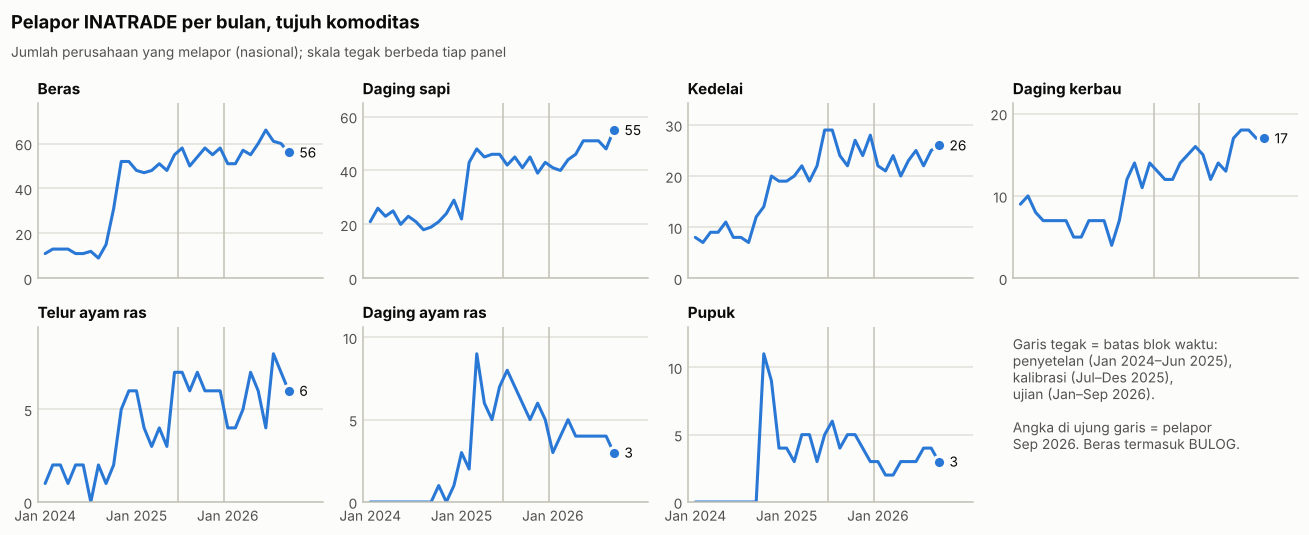

In [8]:
grafik_pelapor(os.path.join(HASIL, 'tahap0', 'pelapor_per_bulan.csv'))

## 2. Validasi satuan: daging sapi dan pupuk
Semua baris INATRADE berlabel "TON", tetapi sebagian diisi dalam kg. Skrip ini hanya memeriksa dan mengelompokkan
(data tidak diubah). Dua pola: **lonjakan sesaat** (≥ 100× median sendiri) dan **skala konsisten besar** (perusahaan
yang selalu mengisi ribuan kali perusahaan lain: 2 di daging sapi, 1 di pupuk). Ketiganya diperlakukan sebagai kg
(perkiraan dari data; disetujui Bu Fitria 14 Nov 2026) dan sudah masuk koreksi satuan Tahap 0.
Pembahasan: `paket/binpas/HASIL_VALIDASI_SATUAN.md`. Daftar per perusahaan ada di `hasil_ulang/satuan/` (internal).

In [9]:
_ = jalan('binpas/validasi_satuan.py', XLSM, os.path.join(HASIL, 'satuan'), 'DAGING SAPI', 'PUPUK')


===== DAGING SAPI: 1347 kepala laporan, 73 perusahaan; median penyaluran antarperusahaan 15.8
laporan per kelompok: {'wajar': 1259, 'lonjakan': 50, 'ragu': 38} | faktor usul: {0.001: 48, 1e-06: 2} | perusahaan dengan lonjakan: 18 | dengan laporan ragu: 19
perusahaan per kelompok skala: {'wajar': 71, 'skala >= 1000x': 2}
total penyaluran per tahun (satuan laporan = "ton"):
      pelapor      mentah  aturan_tahap0  usul_lonjakan  bila_skala_1000x_ternyata_kg
thn                                                                                  
2024       37   1707324.0        26321.0        41477.0                       41477.0
2025       64  27083274.0       451329.0       427095.0                       62811.0
2026       64    132992.0        93722.0        94275.0                       27915.0
  pangsa terbesar / 5 terbesar (mentah): 88% / 97%
  pangsa terbesar / 5 terbesar (aturan Tahap 0): 64% / 88%
  pangsa terbesar / 5 terbesar (usul lonjakan): 65% / 88%
  pangsa terbesar / 5 terb

## 3. Cakupan volume INATRADE terhadap sumber BPS
Penyaluran pelapor INATRADE (pedagang tanpa BULOG, satuan terkoreksi) dibanding pasokan (produksi + impor) dan
konsumsi rumah tangga (Susenas × penduduk) dari WebAPI BPS. Tabel di bawah = **tabel resmi 14 Nov 2026**
(`hasil_cakupan/cakupan_komoditas.csv`). Pembanding beras (Tahap 0): ±1,9% pasokan, ±2,8% konsumsi rumah tangga.

Catatan penyebut: daging kerbau hanya produksi dalam negeri (impor tercatat di HS yang sama dengan daging sapi) dan
pupuk hanya impor empat kode HS, jadi cakupan sebenarnya keduanya lebih kecil. Rincian: `paket/binpas/HASIL_CAKUPAN_KOMODITAS.md`.

In [10]:
NAMA_KOM = {'KEDELAI BAHAN BAKU TEMPE DAN TAHU': 'Kedelai', 'DAGING SAPI': 'Daging sapi', 'DAGING KERBAU': 'Daging kerbau',
            'DAGING AYAM RAS': 'Daging ayam ras', 'TELUR AYAM RAS': 'Telur ayam ras', 'PUPUK': 'Pupuk'}


def ribu(x):
    """Ton -> ribu ton, gaya Indonesia (titik ribuan, koma desimal)."""
    if pd.isna(x) or x == 0:
        return '–'
    v = x / 1000
    s = f'{v:,.1f}' if v < 20 else f'{v:,.0f}'
    return s.replace(',', ' ').replace('.', ',').replace(' ', '.')


def persen(x):
    return '–' if pd.isna(x) else idn(f'{x:.2%}' if x < 0.01 else f'{x:.1%}' if x < 0.1 else f'{x:.0%}')


def tabel_cakupan(path):
    c = pd.read_csv(path)
    c = c[c.tahun >= 2025]        # 2024 tidak ditabelkan: pelapor baru ramai sejak Okt-Nov 2024
    return pd.DataFrame({
        'Komoditas': c.komoditas.map(lambda k: NAMA_KOM.get(k, k)),
        'Tahun': c.tahun.map(lambda y: f'{y} (Jan–Sep)' if y == 2026 else str(y)),
        'Pelapor': c.pelapor, 'Penyaluran INATRADE (ribu ton)': c.penyaluran_ton.map(ribu),
        'Konsumsi RT setahun (ribu ton)': c.konsumsi_rt_ton_setahun.map(ribu),
        'Produksi setahun (ribu ton)': c.produksi_ton_setahun.map(ribu), 'Impor (ribu ton)': c.impor_ton.map(ribu),
        'Penyaluran ÷ pasokan': c.penyaluran_per_pasokan.map(persen),
        'Penyaluran ÷ konsumsi RT': c.penyaluran_per_konsumsi_rt.map(persen)}).reset_index(drop=True)


display(Markdown('**Tabel resmi (14 Nov 2026):**'))
display(tabel_cakupan(R('hasil_cakupan', 'cakupan_komoditas.csv')))

if AMBIL_ULANG_BPS:
    if jalan('binpas/cakupan_komoditas.py', XLSM, BPS_CACHE, os.path.join(HASIL, 'cakupan'), tampil=False,
             log=os.path.join(HASIL, 'layar_cakupan.txt')) == 0:
        display(Markdown('**Dihitung ulang sekarang** (angka BPS bisa sudah direvisi):'))
        display(tabel_cakupan(os.path.join(HASIL, 'cakupan', 'cakupan_komoditas.csv')))

**Tabel resmi (14 Nov 2026):**

,Komoditas,Tahun,Pelapor,Penyaluran INATRADE (ribu ton),Konsumsi RT setahun (ribu ton),Produksi setahun (ribu ton),Impor (ribu ton),Penyaluran ÷ pasokan,Penyaluran ÷ konsumsi RT
0,Daging sapi,2025,64,87,129,499,231,12%,68%
1,Daging sapi,2026 (Jan–Sep),64,27,129,499,136,"5,4%",28%
2,Daging kerbau,2025,17,"6,6","14,8","16,4",–,40%,44%
3,Daging kerbau,2026 (Jan–Sep),20,"7,6","14,8","16,4",–,62%,68%
4,Daging ayam ras,2025,11,108,2.111,4.061,–,"2,7%","5,1%"
5,Daging ayam ras,2026 (Jan–Sep),5,62,2.111,4.061,–,"2,0%","3,9%"
6,Telur ayam ras,2025,8,"5,4",2.121,6.314,–,"0,08%","0,25%"
7,Telur ayam ras,2026 (Jan–Sep),9,"4,4",2.121,6.314,–,"0,09%","0,28%"
8,Kedelai,2025,60,1.578,1.965,–,2.558,62%,80%
9,Kedelai,2026 (Jan–Sep),38,1.328,1.965,–,2.150,62%,90%


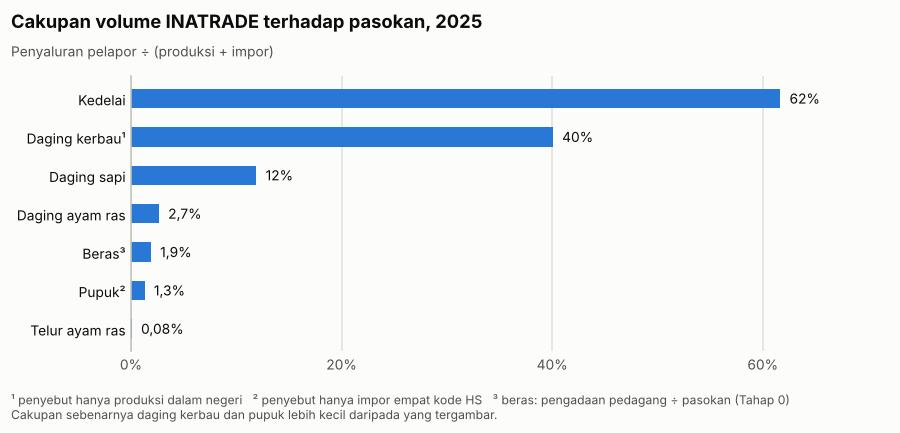

In [11]:
grafik_cakupan_volume(R('hasil_cakupan', 'cakupan_komoditas.csv'))

## 4. Lima komoditas yang diuji: resep, gerbang penyetelan, dan ujian akhir U1

**Alur tiap komoditas** (`adu_versi.py`): adu versi bertahap di blok **penyetelan** (Jan 2024–Jun 2025; 79 kombinasi
untuk beras, 58 untuk lainnya) → resep dikunci → **kalibrasi** (Jul–Des 2025) → **ujian akhir U1** (Jan–Sep 2026,
sekali jalan). Yang dinilai: kemampuan menutup laporan yang bolong (laporan dihapus acak menurut pola bolong yang
sebenarnya, lalu ditebak), dibanding pembanding P\* = data apa adanya ± bobot pelapor. Kunci jawaban = total laporan
yang ada di sel; **ini bukan ukuran keterwakilan pasar** (lihat bagian 3 dan 5).

**Gerbang** (`ambang_ujian.md`, dikunci 11 Nov 2026):
| Gerbang | Ambang |
| --- | --- |
| Lebih baik | CRPS ≥ 10% lebih kecil dari P\* dan MAE median tidak lebih buruk |
| Konsisten | rentang 90% bootstrap per blok bulan dari selisih CRPS seluruhnya < 0 |
| Cakupan rentang 90% | 0,90 di dalam selang Wilson 90% (n efektif) dan cakupan ≥ 80%; setengah lebar selang > 10 poin → "belum bisa diputuskan" |
| Bias | ≤ 3% dan tidak lebih buruk dari P\* |
| Arah perubahan bulanan | sama dengan jawaban benar di ≥ 80% bulan |
| U1 vs penyetelan | masih lebih baik dari P\*; CRPS memburuk ≤ 20% terhadap resep yang sama di blok penyetelan |

Target utama = tingkat **wilayah** (Jawa / Sumatera / Pulau lain) bulanan. Sel dinilai bila berisi ≥ 3 perusahaan.
Gagal di ujian akhir → data apa adanya berlabel "tercatat" (tidak boleh turun peringkat memakai data ujian).

Tiap komoditas di bawah punya tiga sel: **(a)** tabel resmi dari paket tertanam; **(b)** log proses resmi apa adanya
(penyetelan tahap 1a–5, dan turun peringkat bila ada); **(c)** REPLIKASI kalibrasi + ujian dengan resep resmi ke
`hasil_ulang/replikasi_u1_<komoditas>/`, dengan output mentah skrip, lalu dibandingkan dengan `gerbang_U1.csv` resmi.
Replikasi tidak mengulang penyetelan (resep resmi dipakai apa adanya; log penyetelan yang tampil = log run resmi).

**Cara membaca log penyetelan.** Nama versi = `identitas|isian|batas lubang|tambahan|bobot pelapor|ragam|rekonsiliasi`
(mis. `I0|B|99|tdist|None|0.5|0`); `A`, `A3`, `A5` = pembanding (data apa adanya, + bobot pelapor batas 3 / 5). Angka di
kanan = CRPS skala log di tingkat wilayah (tahap 3 di tingkat nasional), makin kecil makin baik. Baris `->` = pilihan
tahap itu (selisih tipis → versi yang lebih sederhana). Tahap: 1a identitas stok, 1b metode isian × batas lubang,
1c tambahan, 2 bobot × ragam, 3 rekonsiliasi, 4 penggabung, 5 koreksi akhir + gerbang. Isian: B = interpolasi / laporan
terakhir, C = pertumbuhan perusahaan sejenis, R1–R4 = regresi panel, R5 = QRF, R6 = CatBoost, R7 = MRP (R5–R7 hanya
beras). Log turun peringkat: satu baris per kandidat (beda satu tahap dari pemenang) dengan status lolos gerbang wilayah.

### 4.1 Beras
Status resmi: **wilayah LOLOS semua gerbang U1**; provinsi lolos dengan catatan (CRPS +13% terhadap resep yang sama di
penyetelan; +28% bila acuannya angka seluruh blok tanpa koreksi; Bu Fitria memutuskan acuan = resep yang sama, sesudah
hasil dilihat); nasional: cakupan belum bisa diputuskan. Resep: koreksi "tanpa" (peringkat 1) gagal gerbang cakupan di
blok penyetelan, lalu turun ke konformal (diputuskan sebelum kalibrasi dan ujian). Rincian: `paket/binpas/HASIL_ADU_BERAS.md`.

In [12]:
tampil_resmi('Beras', 'hasil_adu_beras')

**Beras — resep terkunci:** identitas I0; isian B (semua lubang diisi); tambahan tdist; bobot pelapor tanpa; ragam 0,5×; rekonsiliasi tanpa; koreksi akhir konformal; pembanding P* = A5

**Gerbang di blok PENYETELAN** (dinilai Jan–Jun 2025; hasil penyetelan, bukan ujian):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,75,33,11
CRPS log (resep / P*),"0,038 / 0,265","0,016 / 0,179","0,011 / 0,047"
Perbaikan CRPS,86%,91%,76%
MAE median (resep / P*),"0,052 / 0,320","0,020 / 0,194","0,013 / 0,058"
"Selisih CRPS, rentang 90% bootstrap","-0,260 … -0,195","-0,205 … -0,130","-0,041 … -0,030"
Bias (resep / P*),"+0,3% / -14,0%","+0,1% / -10,5%","0,0% / -1,6%"
Arah perubahan sama,92%,94%,99%
Cakupan rentang 90%,"91,0%","92,8%","95,7%"
Selang Wilson 90% (n efektif),"83,0%–95,4% (59)","79,5%–97,7% (25)","72,4%–99,5% (10)"
Status,lolos semua gerbang,lolos semua gerbang,lolos; cakupan belum bisa diputuskan


**Gerbang U1 RESMI** (ujian akhir Jan–Sep 2026; sekali jalan, sudah terpakai):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,133,57,19
CRPS log (resep / P*),"0,043 / 0,244","0,016 / 0,116","0,011 / 0,048"
Perbaikan CRPS,82%,86%,78%
MAE median (resep / P*),"0,058 / 0,301","0,021 / 0,135","0,015 / 0,055"
"Selisih CRPS, rentang 90% bootstrap","-0,228 … -0,178","-0,134 … -0,075","-0,043 … -0,031"
Bias (resep / P*),"+0,9% / -11,0%","0,0% / -4,3%","+0,3% / -1,3%"
Arah perubahan sama,93%,96%,98%
Cakupan rentang 90%,"93,3%","97,8%","96,9%"
Selang Wilson 90% (n efektif),"87,3%–96,6% (82)","88,1%–99,6% (30)","69,3%–99,8% (8)"
CRPS vs penyetelan (resep yang sama),"+13% (0,038 -> 0,043)","-3% (0,016 -> 0,016)","-4% (0,011 -> 0,011)"


In [13]:
# Log proses RESMI beras: penyetelan (12 Nov 2026, 08.01-09.22 UTC), kalibrasi, dan ujian akhir U1 (13.09 UTC)
tampil_log('hasil_adu_beras', 'log_penyetelan.txt', 'BERAS - log penyetelan resmi (adu versi tahap 1a-5)')
tampil_log('hasil_adu_beras', 'log_kalibrasi.txt', 'BERAS - log kalibrasi resmi (Jul-Des 2025)')
tampil_log('hasil_adu_beras', 'log_ujian.txt', 'BERAS - log ujian akhir U1 resmi (sekali jalan, sudah terpakai)')

BERAS - log penyetelan resmi (adu versi tahap 1a-5)  [paket/binpas/hasil_adu_beras/log_penyetelan.txt]
== penyetelan 2026-11-12 08:01:42 | perusahaan 90, besar 14, wilayah [32, 43, 15] | pola hapus: h=[0.079 0.073], p_ekor=[0.201 0.09 ] | proses 4
[1a identitas] 3 versi, 500 ulangan, 14 detik
cfg
I0|R2|99||3|1.0|0    0.0438
I2|R2|99||3|1.0|0    0.0479
I1|R2|99||3|1.0|0    0.0500
-> identitas: I0; pembanding P* = A5
[1b isian] 44 versi, 500 ulangan, 3062 detik
cfg
I0|R5|99||3|1.0|0     0.0229
I0|B|99||3|1.0|0      0.0251
I0|R5|6||3|1.0|0      0.0252
I0|B|6||3|1.0|0       0.0272
I0|R6a|99||3|1.0|0    0.0279
I0|R6a|6||3|1.0|0     0.0300
I0|C|99||3|1.0|0      0.0317
I0|R6b|99||3|1.0|0    0.0321
I0|R6c|99||3|1.0|0    0.0324
I0|C|6||3|1.0|0       0.0339
I0|R6b|6||3|1.0|0     0.0341
I0|R6c|6||3|1.0|0     0.0343
I0|R4|99||3|1.0|0     0.0433
I0|R1|99||3|1.0|0     0.0436
I0|R2|99||3|1.0|0     0.0439
I0|R3|99||3|1.0|0     0.0441
I0|R4|6||3|1.0|0      0.0456
I0|R1|6||3|1.0|0      0.0458
I0|R2|6||3

**Replikasi beras tidak akan sama persis dengan U1 resmi**, dan itu sudah diketahui sebelumnya. U1 resmi beras
dijalankan dengan kode sebelum commit `fc81529`: (1) seed isian per metode masih memakai `hash()` teks, yang diacak
Python di tiap proses, sehingga tarikan acaknya tidak bisa diulang persis; (2) sel Nov–Des 2025 (lubang akhir yang
mundur ke blok kalibrasi) ikut dinilai, sedangkan kode sekarang hanya menilai sel di dalam blok ujian. Pola hapusnya
sama. Karena itu replikasi dibandingkan juga dengan tabel kepekaan "hanya sel 2026" (`gerbang_U1_peka_2026saja.csv`;
dibuat sesudah hasil U1 dilihat, bukan hasil resmi), yang himpunan selnya sama. Yang perlu dilihat: CRPS pembanding
P\* (tidak memakai tarikan acak isian) harus sama dengan tabel kepekaan, CRPS resep berselisih tipis, dan status
gerbang sama. Selisih relatif yang besar wajar muncul di kolom yang nilainya mendekati nol (mis. bias wilayah ±0,05%).

In [14]:
_g = replikasi('BERAS', 'hasil_adu_beras')
if _g is not None:
    display(Markdown('**Replikasi vs U1 resmi** (resmi ikut menilai sel Nov–Des 2025):'))
    print(vonis(*tampil_banding(baca_gerbang(R('hasil_adu_beras', 'gerbang_U1.csv')), _g)))
    display(Markdown('**Replikasi vs tabel kepekaan "hanya sel 2026"** (himpunan sel sama; seed isian berbeda):'))
    print(vonis(*tampil_banding(baca_gerbang(R('hasil_adu_beras', 'gerbang_U1_peka_2026saja.csv')), _g, 'kepekaan 2026'),
                acuan='tabel kepekaan'))
    display(Markdown('**Gerbang replikasi beras** (acuan "memburuk" = resep yang sama di blok penyetelan):'))
    display(tabel_gerbang(_g, acuan=acuan_penyetelan('hasil_adu_beras')))

REPLIKASI (bukan ujian baru) -> hasil_ulang/replikasi_u1_beras


== kalibrasi 2026-11-16 14:05:27 | BERAS | perusahaan 90, besar 14, wilayah [32, 43, 15] | pola hapus: h=[0.079 0.073], p_ekor=[0.201 0.09 ] | proses 4


== KALIBRASI: bias dan pelebar Q per tingkat/jenis lubang
             bias      n     Q50     Q80     Q90     Q95
prov/tengah   0.0   34.0  0.0008  0.0093  0.0507  0.4704
prov/akhir    0.0   41.0  0.0008  0.0069  0.0438  0.1199
wil/tengah    0.0   33.0  0.0005  0.0069  0.0150  0.1640
wil/akhir     0.0   33.0  0.0005  0.0069  0.0150  0.1640
nas/tengah    0.0  119.0  0.0004  0.0048  0.0123  0.0306
nas/akhir     0.0  119.0  0.0004  0.0048  0.0123  0.0306
[adu_versi.py: keluar 0, 14 detik]


== ujian 2026-11-16 14:05:33 | BERAS | perusahaan 90, besar 14, wilayah [32, 43, 15] | pola hapus: h=[0.079 0.073], p_ekor=[0.201 0.09 ] | proses 4


== GERBANG U1 (prov / wil / nas); pembanding P* = A5
                            0          1         2
tingkat                  prov        wil       nas
sel_bulan                 119         51        17
crps                 0.043372   0.016799  0.011531
crps_pembanding      0.243583   0.123132  0.052302
perbaikan            0.821943   0.863567  0.779529
mae                  0.058715   0.021825  0.015717
mae_pembanding       0.301339   0.142953  0.060224
selisih_lo          -0.228477  -0.141413 -0.046339
selisih_hi          -0.173701  -0.079938 -0.035123
cakupan              0.951919   0.978228  0.971999
n_efektif           72.472758  16.678243  6.623211
wilson_lo            0.891925   0.825269   0.67188
wilson_hi            0.979379   0.997666  0.998304
bias                 0.015218   0.000553  0.004081
bias_pembanding     -0.108392  -0.049583  -0.01353
L_lebih_baik             True       True      True
L_konsisten              True       True      True
L_cakupan                True

**Replikasi vs U1 resmi** (resmi ikut menilai sel Nov–Des 2025):

... (3 outputs left out)

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan (kepekaan 2026 / replikasi),119 / 119,51 / 51,17 / 17
CRPS log,"0,0431 / 0,0434","0,0167 / 0,0168","0,0116 / 0,0115"
CRPS pembanding P*,"0,2436 / 0,2436","0,1231 / 0,1231","0,0523 / 0,0523"
Bias,"+1,51% / +1,52%","+0,04% / +0,06%","+0,41% / +0,41%"
Cakupan 90%,"94,3% / 95,2%","97,6% / 97,8%","96,7% / 97,2%"
"Status gerbang (tanpa ""memburuk"")",lolos semua gerbang / lolos semua gerbang,lolos semua gerbang / lolos semua gerbang,lolos; cakupan belum bisa diputuskan / lolos; cakupan belum bisa diputuskan


BERBEDA dari tabel kepekaan: CRPS berselisih paling besar 0,8%; status gerbang SAMA; selisih relatif terbesar 44% ada di kolom n_efektif (nasional)


**Gerbang replikasi beras** (acuan "memburuk" = resep yang sama di blok penyetelan):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,119,51,17
CRPS log (resep / P*),"0,043 / 0,244","0,017 / 0,123","0,012 / 0,052"
Perbaikan CRPS,82%,86%,78%
MAE median (resep / P*),"0,059 / 0,301","0,022 / 0,143","0,016 / 0,060"
"Selisih CRPS, rentang 90% bootstrap","-0,228 … -0,174","-0,141 … -0,080","-0,046 … -0,035"
Bias (resep / P*),"+1,5% / -10,8%","+0,1% / -5,0%","+0,4% / -1,4%"
Arah perubahan sama,93%,96%,98%
Cakupan rentang 90%,"95,2%","97,8%","97,2%"
Selang Wilson 90% (n efektif),"89,2%–97,9% (72)","82,5%–99,8% (17)","67,2%–99,8% (7)"
CRPS vs penyetelan (resep yang sama),"+14% (0,038 -> 0,043)","+3% (0,016 -> 0,017)","+4% (0,011 -> 0,012)"


### 4.2 Daging sapi (satuan terkoreksi)
Status resmi: **wilayah LOLOS semua gerbang U1**; provinsi dan nasional gagal gerbang bias. Hasil ini bergantung pada
koreksi satuan dua perusahaan (perkiraan dari data), dan resepnya hasil turun peringkat di blok penyetelan (pemenang
semula gagal bias −4,8%; resep "semua lubang diisi" lolos). Rincian: `paket/binpas/HASIL_ADU_KOMODITAS.md`.

In [15]:
tampil_resmi('Daging sapi (satuan terkoreksi)', 'hasil_adu_daging_sapi_v2')

**Daging sapi (satuan terkoreksi) — resep terkunci:** identitas I0; isian B (semua lubang diisi); tambahan ciri + pola + ragamkel + tdist; bobot pelapor tanpa; ragam 0,5×; rekonsiliasi tanpa; koreksi akhir konformal; pembanding P* = A5

**Gerbang di blok PENYETELAN** (dinilai Jan–Jun 2025; hasil penyetelan, bukan ujian):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,31,33,11
CRPS log (resep / P*),"0,150 / 0,222","0,134 / 0,340","0,089 / 0,115"
Perbaikan CRPS,33%,61%,23%
MAE median (resep / P*),"0,181 / 0,274","0,161 / 0,391","0,106 / 0,139"
"Selisih CRPS, rentang 90% bootstrap","-0,112 … -0,035","-0,357 … -0,083","-0,043 … -0,008"
Bias (resep / P*),"+3,1% / -8,0%","+0,1% / -18,5%","-0,7% / -3,2%"
Arah perubahan sama,89%,88%,89%
Cakupan rentang 90%,"95,4%","92,1%","92,4%"
Selang Wilson 90% (n efektif),"84,8%–98,7% (31)","80,9%–97,0% (33)","69,6%–98,5% (11)"
Status,gagal (bias),lolos semua gerbang,lolos; cakupan belum bisa diputuskan


**Gerbang U1 RESMI** (ujian akhir Jan–Sep 2026; sekali jalan, sudah terpakai):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,49,51,17
CRPS log (resep / P*),"0,116 / 0,426","0,061 / 0,168","0,048 / 0,089"
Perbaikan CRPS,73%,64%,46%
MAE median (resep / P*),"0,150 / 0,493","0,070 / 0,207","0,061 / 0,106"
"Selisih CRPS, rentang 90% bootstrap","-0,421 … -0,201","-0,134 … -0,086","-0,052 … -0,030"
Bias (resep / P*),"+4,6% / -23,7%","+1,1% / -6,2%","+3,4% / -2,4%"
Arah perubahan sama,88%,86%,94%
Cakupan rentang 90%,"92,2%","96,6%","93,5%"
Selang Wilson 90% (n efektif),"83,5%–96,5% (49)","89,5%–98,9% (51)","75,0%–98,6% (15)"
CRPS vs penyetelan (resep yang sama),"-23% (0,150 -> 0,116)","-55% (0,134 -> 0,061)","-46% (0,089 -> 0,048)"


In [16]:
# Log proses RESMI daging sapi (satuan terkoreksi): penyetelan, lalu turun peringkat karena pemenang gagal gerbang bias
tampil_log('hasil_adu_daging_sapi_v2', 'log_penyetelan.txt', 'DAGING SAPI - log penyetelan resmi (satuan terkoreksi)')
tampil_log('hasil_adu_daging_sapi_v2', 'log_turun_peringkat.txt', 'DAGING SAPI - log turun peringkat resmi (blok penyetelan saja)')

DAGING SAPI - log penyetelan resmi (satuan terkoreksi)  [paket/binpas/hasil_adu_daging_sapi_v2/log_penyetelan.txt]
== penyetelan 2026-11-14 15:12:32 | DAGING SAPI | perusahaan 73, besar 11, wilayah [61, 5, 7] | pola hapus: h=[0.101 0.047], p_ekor=[0.206 0.103] | proses 4
[1a identitas] 3 versi, 500 ulangan, 17 detik
cfg
I0|R2|99||3|1.0|0    0.1711
I2|R2|99||3|1.0|0    0.1730
I1|R2|99||3|1.0|0    0.1785
-> identitas: I0; pembanding P* = A5
[1b isian] 24 versi, 500 ulangan, 31 detik
cfg
I0|C|2||3|1.0|0      0.1373
I0|B|2||3|1.0|0      0.1403
I0|C|3||3|1.0|0      0.1419
I0|C|6||3|1.0|0      0.1445
I0|B|3||3|1.0|0      0.1457
I0|B|6||3|1.0|0      0.1506
I0|C|99||3|1.0|0     0.1525
I0|B|99||3|1.0|0     0.1624
I0|R3|99||3|1.0|0    0.1709
I0|R3|2||3|1.0|0     0.1719
I0|R3|3||3|1.0|0     0.1725
I0|R3|6||3|1.0|0     0.1735
I0|R1|2||3|1.0|0     0.1761
I0|R1|99||3|1.0|0    0.1763
I0|R2|2||3|1.0|0     0.1763
I0|R2|99||3|1.0|0    0.1765
I0|R1|3||3|1.0|0     0.1770
I0|R2|3||3|1.0|0     0.1771
I0|R1|

In [17]:
_g = replikasi('DAGING SAPI', 'hasil_adu_daging_sapi_v2')
if _g is not None:
    print(vonis(*tampil_banding(baca_gerbang(R('hasil_adu_daging_sapi_v2', 'gerbang_U1.csv')), _g)))

REPLIKASI (bukan ujian baru) -> hasil_ulang/replikasi_u1_daging_sapi_v2


== kalibrasi 2026-11-16 14:05:54 | DAGING SAPI | perusahaan 73, besar 11, wilayah [61, 5, 7] | pola hapus: h=[0.101 0.047], p_ekor=[0.206 0.103] | proses 4


== KALIBRASI: bias dan pelebar Q per tingkat/jenis lubang
             bias     n     Q50     Q80     Q90     Q95
prov/tengah   0.0  33.0  0.0006  0.0048  0.0205  1.3271
prov/akhir    0.0  33.0  0.0006  0.0048  0.0205  1.3271
wil/tengah    0.0  33.0 -0.0063  0.0092  0.0275  0.6305
wil/akhir     0.0  33.0 -0.0063  0.0092  0.0275  0.6305
nas/tengah    0.0  77.0 -0.0000  0.0016  0.0113  0.0453
nas/akhir     0.0  77.0 -0.0000  0.0016  0.0113  0.0453
[adu_versi.py: keluar 0, 13 detik]


== ujian 2026-11-16 14:05:59 | DAGING SAPI | perusahaan 73, besar 11, wilayah [61, 5, 7] | pola hapus: h=[0.101 0.047], p_ekor=[0.206 0.103] | proses 4


== GERBANG U1 (prov / wil / nas); pembanding P* = A5
                           0         1          2
tingkat                 prov       wil        nas
sel_bulan                 49        51         17
crps                0.115514  0.060536   0.047745
crps_pembanding     0.425829  0.168126   0.088962
perbaikan           0.728732  0.639939   0.463316
mae                  0.15033  0.070362   0.061314
mae_pembanding      0.493249  0.206949   0.105983
selisih_lo         -0.421454 -0.133886    -0.0521
selisih_hi         -0.200707 -0.086446  -0.029894
cakupan              0.92236  0.965833   0.935053
n_efektif               49.0      51.0  14.781561
wilson_lo           0.835168  0.895312   0.749711
wilson_hi           0.965343  0.989411   0.985755
bias                0.045703  0.011416   0.033722
bias_pembanding    -0.236558 -0.062082  -0.024079
L_lebih_baik            True      True       True
L_konsisten             True      True       True
L_cakupan               True      True       Tr

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan (resmi / replikasi),49 / 49,51 / 51,17 / 17
CRPS log,"0,1155 / 0,1155","0,0605 / 0,0605","0,0477 / 0,0477"
CRPS pembanding P*,"0,4258 / 0,4258","0,1681 / 0,1681","0,0890 / 0,0890"
Bias,"+4,57% / +4,57%","+1,14% / +1,14%","+3,37% / +3,37%"
Cakupan 90%,"92,2% / 92,2%","96,6% / 96,6%","93,5% / 93,5%"
"Status gerbang (tanpa ""memburuk"")",gagal (bias) / gagal (bias),lolos semua gerbang / lolos semua gerbang,gagal (bias) / gagal (bias)


SAMA PERSIS dengan hasil resmi (semua kolom angka identik)


### 4.3 Kedelai
Status resmi: **wilayah GAGAL gerbang bias** (+5,0%, batas 3%) → "tercatat"; provinsi lolos semua gerbang (dilaporkan
dengan catatan); nasional: cakupan belum bisa diputuskan. Telusur sesudah hasil (bukan dasar keputusan): bias berasal
dari "Pulau lain" (4 sel-bulan; satu perusahaan memegang 91% volume wilayah itu).

In [18]:
tampil_resmi('Kedelai', 'hasil_adu_kedelai')

**Kedelai — resep terkunci:** identitas I0; isian B (semua lubang diisi); tambahan tdist; bobot pelapor tanpa; ragam 1,0×; rekonsiliasi tanpa; koreksi akhir konformal; pembanding P* = A3

**Gerbang di blok PENYETELAN** (dinilai Jan–Jun 2025; hasil penyetelan, bukan ujian):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,24,25,11
CRPS log (resep / P*),"0,038 / 0,321","0,081 / 0,154","0,014 / 0,090"
Perbaikan CRPS,88%,47%,84%
MAE median (resep / P*),"0,045 / 0,379","0,092 / 0,182","0,016 / 0,104"
"Selisih CRPS, rentang 90% bootstrap","-0,337 … -0,229","-0,085 … -0,057","-0,084 … -0,067"
Bias (resep / P*),"+2,4% / -10,2%","+3,0% / -5,8%","+0,3% / -1,6%"
Arah perubahan sama,92%,96%,95%
Cakupan rentang 90%,"95,7%","88,6%","97,6%"
Selang Wilson 90% (n efektif),"83,1%–99,0% (24)","74,2%–95,5% (25)","76,6%–99,8% (11)"
Status,lolos semua gerbang,lolos; cakupan belum bisa diputuskan,lolos; cakupan belum bisa diputuskan


**Gerbang U1 RESMI** (ujian akhir Jan–Sep 2026; sekali jalan, sudah terpakai):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,43,38,17
CRPS log (resep / P*),"0,037 / 0,275","0,052 / 0,318","0,010 / 0,093"
Perbaikan CRPS,87%,84%,89%
MAE median (resep / P*),"0,047 / 0,339","0,070 / 0,343","0,012 / 0,108"
"Selisih CRPS, rentang 90% bootstrap","-0,255 … -0,220","-0,456 … -0,106","-0,092 … -0,074"
Bias (resep / P*),"-0,4% / -11,6%","+5,0% / -19,6%","-0,2% / -1,7%"
Arah perubahan sama,91%,97%,92%
Cakupan rentang 90%,"96,7%","95,2%","96,4%"
Selang Wilson 90% (n efektif),"88,5%–99,1% (41)","82,4%–98,8% (24)","59,4%–99,8% (5)"
CRPS vs penyetelan (resep yang sama),"-3% (0,038 -> 0,037)","-36% (0,081 -> 0,052)","-29% (0,014 -> 0,010)"


In [19]:
# Log proses RESMI kedelai: penyetelan
tampil_log('hasil_adu_kedelai', 'log_penyetelan.txt', 'KEDELAI - log penyetelan resmi (adu versi tahap 1a-5)')

KEDELAI - log penyetelan resmi (adu versi tahap 1a-5)  [paket/binpas/hasil_adu_kedelai/log_penyetelan.txt]
== penyetelan 2026-11-14 13:30:04 | KEDELAI BAHAN BAKU TEMPE DAN TAHU | perusahaan 73, besar 9, wilayah [42, 24, 7] | pola hapus: h=[0.07  0.082], p_ekor=[0.38  0.151] | proses 4
[1a identitas] 3 versi, 500 ulangan, 13 detik
cfg
I0|R2|99||3|1.0|0    0.0849
I2|R2|99||3|1.0|0    0.0888
I1|R2|99||3|1.0|0    0.0901
-> identitas: I0; pembanding P* = A3
[1b isian] 24 versi, 500 ulangan, 19 detik
cfg
I0|C|99||3|1.0|0     0.0555
I0|B|99||3|1.0|0     0.0558
I0|C|6||3|1.0|0      0.0575
I0|B|6||3|1.0|0      0.0582
I0|C|3||3|1.0|0      0.0610
I0|B|3||3|1.0|0      0.0618
I0|C|2||3|1.0|0      0.0684
I0|B|2||3|1.0|0      0.0695
I0|R2|99||3|1.0|0    0.0790
I0|R3|99||3|1.0|0    0.0795
I0|R2|6||3|1.0|0     0.0805
I0|R3|6||3|1.0|0     0.0814
I0|R1|99||3|1.0|0    0.0829
I0|R4|99||3|1.0|0    0.0841
I0|R2|3||3|1.0|0     0.0842
I0|R1|6||3|1.0|0     0.0846
I0|R3|3||3|1.0|0     0.0853
I0|R4|6||3|1.0|0    

In [20]:
_g = replikasi('KEDELAI BAHAN BAKU TEMPE DAN TAHU', 'hasil_adu_kedelai')
if _g is not None:
    print(vonis(*tampil_banding(baca_gerbang(R('hasil_adu_kedelai', 'gerbang_U1.csv')), _g)))

REPLIKASI (bukan ujian baru) -> hasil_ulang/replikasi_u1_kedelai


== kalibrasi 2026-11-16 14:06:18 | KEDELAI BAHAN BAKU TEMPE DAN TAHU | perusahaan 73, besar 9, wilayah [42, 24, 7] | pola hapus: h=[0.07  0.082], p_ekor=[0.38  0.151] | proses 4


== KALIBRASI: bias dan pelebar Q per tingkat/jenis lubang
             bias     n     Q50     Q80     Q90     Q95
prov/tengah   0.0  33.0 -0.0015  0.0000  0.0000  0.0222
prov/akhir    0.0  33.0 -0.0015  0.0000  0.0000  0.0222
wil/tengah    0.0  22.0 -0.0003  0.0001  0.0085  0.3827
wil/akhir     0.0  22.0 -0.0003  0.0001  0.0085  0.3827
nas/tengah    0.0  66.0 -0.0007 -0.0001  0.0000  0.0004
nas/akhir     0.0  66.0 -0.0007 -0.0001  0.0000  0.0004
[adu_versi.py: keluar 0, 13 detik]


== ujian 2026-11-16 14:06:22 | KEDELAI BAHAN BAKU TEMPE DAN TAHU | perusahaan 73, besar 9, wilayah [42, 24, 7] | pola hapus: h=[0.07  0.082], p_ekor=[0.38  0.151] | proses 4


== GERBANG U1 (prov / wil / nas); pembanding P* = A3
                            0          1         2
tingkat                  prov        wil       nas
sel_bulan                  43         38        17
crps                 0.036592    0.05205  0.010154
crps_pembanding      0.274592    0.31768  0.093405
perbaikan             0.86674   0.836156  0.891295
mae                  0.047037   0.070281  0.011911
mae_pembanding       0.338622   0.343284  0.107797
selisih_lo          -0.254645  -0.455707 -0.091888
selisih_hi          -0.219704  -0.105941 -0.074242
cakupan              0.967098    0.95162  0.963804
n_efektif           41.167309  24.143605  4.780008
wilson_lo            0.885444   0.824178  0.594362
wilson_hi            0.991133   0.988029  0.997938
bias                -0.003529   0.049735 -0.001526
bias_pembanding     -0.115504  -0.196441 -0.016803
L_lebih_baik             True       True      True
L_konsisten              True       True      True
L_cakupan                True

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan (resmi / replikasi),43 / 43,38 / 38,17 / 17
CRPS log,"0,0366 / 0,0366","0,0520 / 0,0520","0,0102 / 0,0102"
CRPS pembanding P*,"0,2746 / 0,2746","0,3177 / 0,3177","0,0934 / 0,0934"
Bias,"-0,35% / -0,35%","+4,97% / +4,97%","-0,15% / -0,15%"
Cakupan 90%,"96,7% / 96,7%","95,2% / 95,2%","96,4% / 96,4%"
"Status gerbang (tanpa ""memburuk"")",lolos semua gerbang / lolos semua gerbang,gagal (bias) / gagal (bias),lolos; cakupan belum bisa diputuskan / lolos; cakupan belum bisa diputuskan


SAMA PERSIS dengan hasil resmi (semua kolom angka identik)


### 4.4 Daging kerbau
Status resmi: **wilayah GAGAL gerbang bias** (+5,7%) → "tercatat". Resep R4 (regresi panel dengan musim) adalah hasil
turun peringkat di blok penyetelan (pemenang semula R3 gagal bias −7,9%). Telusur sesudah hasil: bias berasal dari
Sumatera (dua perusahaan memegang 91%). Di blok penyetelan tidak ada provinsi dengan ≥ 3 pelapor. Tambahan "luar"
(peubah luar) yang ikut tertulis di resep tidak berpengaruh: data peubah luar hanya ada untuk beras.

In [21]:
tampil_resmi('Daging kerbau', 'hasil_adu_daging_kerbau')

**Daging kerbau — resep terkunci:** identitas I0; isian R4 (semua lubang diisi); tambahan ciri + luar + pola; bobot pelapor tanpa; ragam 0,5×; rekonsiliasi tanpa; koreksi akhir tanpa; pembanding P* = A5

**Gerbang di blok PENYETELAN** (dinilai Jan–Jun 2025; hasil penyetelan, bukan ujian):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,tidak ada sel,25,11
CRPS log (resep / P*),–,"0,147 / 0,509","0,073 / 0,180"
Perbaikan CRPS,–,71%,59%
MAE median (resep / P*),–,"0,211 / 0,609","0,099 / 0,228"
"Selisih CRPS, rentang 90% bootstrap",–,"-0,589 … -0,170","-0,167 … -0,064"
Bias (resep / P*),–,"+2,4% / -28,8%","+0,2% / -1,2%"
Arah perubahan sama,–,88%,96%
Cakupan rentang 90%,–,"80,7%","81,5%"
Selang Wilson 90% (n efektif),–,"65,1%–90,4% (25)","25,5%–98,3% (2)"
Status,–,lolos; cakupan belum bisa diputuskan,lolos; cakupan belum bisa diputuskan


**Gerbang U1 RESMI** (ujian akhir Jan–Sep 2026; sekali jalan, sudah terpakai):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,9,49,17
CRPS log (resep / P*),"0,218 / 0,837","0,138 / 0,276","0,094 / 0,162"
Perbaikan CRPS,74%,50%,42%
MAE median (resep / P*),"0,337 / 0,867","0,192 / 0,326","0,135 / 0,187"
"Selisih CRPS, rentang 90% bootstrap","-0,800 … -0,427","-0,181 … -0,095","-0,090 … -0,047"
Bias (resep / P*),"-17,4% / -37,7%","+5,7% / -12,3%","+3,0% / -4,8%"
Arah perubahan sama,79%,80%,88%
Cakupan rentang 90%,"96,6%","85,5%","82,4%"
Selang Wilson 90% (n efektif),"71,9%–99,7% (9)","75,4%–91,9% (49)","61,1%–93,3% (14)"
CRPS vs penyetelan (resep yang sama),–,"-6% (0,147 -> 0,138)","+29% (0,073 -> 0,094)"


In [22]:
# Log proses RESMI daging kerbau: penyetelan, lalu turun peringkat karena pemenang (R3) gagal gerbang bias
tampil_log('hasil_adu_daging_kerbau', 'log_penyetelan.txt', 'DAGING KERBAU - log penyetelan resmi')
tampil_log('hasil_adu_daging_kerbau', 'log_turun_peringkat.txt', 'DAGING KERBAU - log turun peringkat resmi (blok penyetelan saja)')

DAGING KERBAU - log penyetelan resmi  [paket/binpas/hasil_adu_daging_kerbau/log_penyetelan.txt]
== penyetelan 2026-11-14 13:34:38 | DAGING KERBAU | perusahaan 22, besar 7, wilayah [13, 4, 5] | pola hapus: h=[0.087 0.094], p_ekor=[0.268 0.173] | proses 4
[1a identitas] 3 versi, 500 ulangan, 9 detik
cfg
I0|R2|99||3|1.0|0    0.2377
I2|R2|99||3|1.0|0    0.2417
I1|R2|99||3|1.0|0    0.2474
-> identitas: I0; pembanding P* = A5
[1b isian] 24 versi, 500 ulangan, 14 detik
cfg
I0|R2|99||3|1.0|0    0.2176
I0|R1|99||3|1.0|0    0.2178
I0|R4|6||3|1.0|0     0.2190
I0|R4|99||3|1.0|0    0.2195
I0|R4|3||3|1.0|0     0.2210
I0|R4|2||3|1.0|0     0.2213
I0|R2|6||3|1.0|0     0.2217
I0|R3|99||3|1.0|0    0.2217
I0|R1|6||3|1.0|0     0.2220
I0|R2|3||3|1.0|0     0.2237
I0|R1|3||3|1.0|0     0.2241
I0|R3|6||3|1.0|0     0.2241
I0|R2|2||3|1.0|0     0.2241
I0|R1|2||3|1.0|0     0.2246
I0|R3|3||3|1.0|0     0.2261
I0|R3|2||3|1.0|0     0.2265
I0|B|2||3|1.0|0      0.2973
I0|B|3||3|1.0|0      0.2996
I0|B|6||3|1.0|0      0.30

In [23]:
_g = replikasi('DAGING KERBAU', 'hasil_adu_daging_kerbau')
if _g is not None:
    print(vonis(*tampil_banding(baca_gerbang(R('hasil_adu_daging_kerbau', 'gerbang_U1.csv')), _g)))

REPLIKASI (bukan ujian baru) -> hasil_ulang/replikasi_u1_daging_kerbau


== kalibrasi 2026-11-16 14:06:39 | DAGING KERBAU | perusahaan 22, besar 7, wilayah [13, 4, 5] | pola hapus: h=[0.087 0.094], p_ekor=[0.268 0.173] | proses 4


== KALIBRASI: bias dan pelebar Q per tingkat/jenis lubang
             bias     n     Q50     Q80     Q90     Q95
prov/tengah   0.0  44.0  0.0006  0.0014  0.0066  0.0202
prov/akhir    0.0  44.0  0.0006  0.0014  0.0066  0.0202
wil/tengah    0.0  33.0  0.0003  0.0035  0.0074  1.2729
wil/akhir     0.0  33.0  0.0003  0.0035  0.0074  1.2729
nas/tengah    0.0  44.0  0.0006  0.0014  0.0066  0.0202
nas/akhir     0.0  44.0  0.0006  0.0014  0.0066  0.0202
[adu_versi.py: keluar 0, 13 detik]


== ujian 2026-11-16 14:06:44 | DAGING KERBAU | perusahaan 22, besar 7, wilayah [13, 4, 5] | pola hapus: h=[0.087 0.094], p_ekor=[0.268 0.173] | proses 4


== GERBANG U1 (prov / wil / nas); pembanding P* = A5
                           0         1          2
tingkat                 prov       wil        nas
sel_bulan                  9        49         17
crps                0.218027  0.138354   0.094397
crps_pembanding      0.83721  0.276293   0.162393
perbaikan           0.739579  0.499249   0.418708
mae                 0.336536  0.191812   0.135007
mae_pembanding      0.866704  0.325979    0.18724
selisih_lo         -0.800255 -0.180949   -0.08983
selisih_hi         -0.426517  -0.09473  -0.046681
cakupan             0.965804  0.855001   0.823828
n_efektif                9.0      49.0  14.166018
wilson_lo           0.719457  0.753758   0.610723
wilson_hi           0.996795  0.919086   0.933058
bias               -0.173844  0.056653   0.030018
bias_pembanding    -0.377122 -0.122857  -0.048122
L_lebih_baik            True      True       True
L_konsisten             True      True       True
L_cakupan               True      True       Tr

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan (resmi / replikasi),9 / 9,49 / 49,17 / 17
CRPS log,"0,2180 / 0,2180","0,1384 / 0,1384","0,0944 / 0,0944"
CRPS pembanding P*,"0,8372 / 0,8372","0,2763 / 0,2763","0,1624 / 0,1624"
Bias,"-17,38% / -17,38%","+5,67% / +5,67%","+3,00% / +3,00%"
Cakupan 90%,"96,6% / 96,6%","85,5% / 85,5%","82,4% / 82,4%"
"Status gerbang (tanpa ""memburuk"")","gagal (bias, arah) / gagal (bias, arah)",gagal (bias) / gagal (bias),gagal (bias) / gagal (bias)


SAMA PERSIS dengan hasil resmi (semua kolom angka identik)


### 4.5 Telur ayam ras
Status resmi: **GAGAL** → "tercatat". Di wilayah gerbang lebih baik, konsisten, bias, dan arah lolos, tetapi CRPS 5×
lebih besar daripada di penyetelan (penyetelan hanya 6 sel-bulan), jadi gagal gerbang "memburuk ≤ 20%".

In [24]:
tampil_resmi('Telur ayam ras', 'hasil_adu_telur_ayam')

**Telur ayam ras — resep terkunci:** identitas I1; isian B (semua lubang diisi); tambahan tdist; bobot pelapor tanpa; ragam 1,0×; rekonsiliasi tanpa; koreksi akhir tanpa; pembanding P* = A3

**Gerbang di blok PENYETELAN** (dinilai Jan–Jun 2025; hasil penyetelan, bukan ujian):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,3,6,11
CRPS log (resep / P*),"0,020 / 0,121","0,028 / 0,370","0,092 / 0,339"
Perbaikan CRPS,83%,92%,73%
MAE median (resep / P*),"0,026 / 0,123","0,037 / 0,372","0,100 / 0,373"
"Selisih CRPS, rentang 90% bootstrap","-0,145 … -0,079","-0,442 … -0,241","-0,340 … -0,146"
Bias (resep / P*),"-0,8% / -8,1%","+2,2% / -12,8%","-2,8% / -15,7%"
Arah perubahan sama,88%,97%,92%
Cakupan rentang 90%,"86,7%","89,4%","81,8%"
Selang Wilson 90% (n efektif),"40,2%–98,5% (3)","56,1%–98,2% (6)","55,3%–94,2% (10)"
Status,lolos; cakupan belum bisa diputuskan,lolos; cakupan belum bisa diputuskan,lolos; cakupan belum bisa diputuskan


**Gerbang U1 RESMI** (ujian akhir Jan–Sep 2026; sekali jalan, sudah terpakai):

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,4,17,17
CRPS log (resep / P*),"0,148 / 0,792","0,139 / 0,421","0,140 / 0,274"
Perbaikan CRPS,81%,67%,49%
MAE median (resep / P*),"0,160 / 0,792","0,153 / 0,463","0,152 / 0,311"
"Selisih CRPS, rentang 90% bootstrap","-1,099 … -0,189","-0,362 … -0,216","-0,167 … -0,102"
Bias (resep / P*),"+6,4% / -32,0%","+2,5% / -21,5%","-4,9% / -8,8%"
Arah perubahan sama,98%,96%,95%
Cakupan rentang 90%,"58,4%","80,5%","76,3%"
Selang Wilson 90% (n efektif),"23,5%–86,5% (4)","61,0%–91,6% (17)","53,0%–90,2% (12)"
CRPS vs penyetelan (resep yang sama),"+629% (0,020 -> 0,148)","+397% (0,028 -> 0,139)","+52% (0,092 -> 0,140)"


In [25]:
# Log proses RESMI telur ayam ras: penyetelan
tampil_log('hasil_adu_telur_ayam', 'log_penyetelan.txt', 'TELUR AYAM RAS - log penyetelan resmi (adu versi tahap 1a-5)')

TELUR AYAM RAS - log penyetelan resmi (adu versi tahap 1a-5)  [paket/binpas/hasil_adu_telur_ayam/log_penyetelan.txt]
== penyetelan 2026-11-14 13:36:36 | TELUR AYAM RAS | perusahaan 11, besar 3, wilayah [5, 5, 1] | pola hapus: h=[0.163 0.083], p_ekor=[0.308 0.162] | proses 4
[1a identitas] 3 versi, 493 ulangan, 4 detik
cfg
I2|R2|99||3|1.0|0    0.0663
I1|R2|99||3|1.0|0    0.0663
I0|R2|99||3|1.0|0    0.0672
-> identitas: I1; pembanding P* = A3
[1b isian] 24 versi, 493 ulangan, 13 detik
cfg
I1|R3|99||3|1.0|0    0.0489
I1|R2|99||3|1.0|0    0.0498
I1|R1|99||3|1.0|0    0.0505
I1|R3|6||3|1.0|0     0.0538
I1|R2|6||3|1.0|0     0.0546
I1|R1|6||3|1.0|0     0.0553
I1|B|99||3|1.0|0     0.0562
I1|R4|99||3|1.0|0    0.0580
I1|B|6||3|1.0|0      0.0609
I1|R4|6||3|1.0|0     0.0625
I1|R3|3||3|1.0|0     0.0718
I1|R2|3||3|1.0|0     0.0723
I1|R1|3||3|1.0|0     0.0731
I1|B|3||3|1.0|0      0.0777
I1|R3|2||3|1.0|0     0.0788
I1|R2|2||3|1.0|0     0.0793
I1|R1|2||3|1.0|0     0.0801
I1|R4|3||3|1.0|0     0.0802
I1|C

In [26]:
_g = replikasi('TELUR AYAM RAS', 'hasil_adu_telur_ayam')
if _g is not None:
    print(vonis(*tampil_banding(baca_gerbang(R('hasil_adu_telur_ayam', 'gerbang_U1.csv')), _g)))

REPLIKASI (bukan ujian baru) -> hasil_ulang/replikasi_u1_telur_ayam


== kalibrasi 2026-11-16 14:07:00 | TELUR AYAM RAS | perusahaan 11, besar 3, wilayah [5, 5, 1] | pola hapus: h=[0.163 0.083], p_ekor=[0.308 0.162] | proses 4


== KALIBRASI: bias dan pelebar Q per tingkat/jenis lubang
             bias     n  Q50     Q80     Q90     Q95
prov/tengah   0.0  37.0  0.0  0.0466  0.1784  0.7402
prov/akhir    0.0  37.0  0.0  0.0466  0.1784  0.7402
wil/tengah    0.0  37.0  0.0  0.0466  0.1784  0.7402
wil/akhir     0.0  37.0  0.0  0.0466  0.1784  0.7402
nas/tengah    0.0  37.0  0.0  0.0466  0.1784  0.7402
nas/akhir     0.0  37.0  0.0  0.0466  0.1784  0.7402


[adu_versi.py: keluar 0, 11 detik]


== ujian 2026-11-16 14:07:03 | TELUR AYAM RAS | perusahaan 11, besar 3, wilayah [5, 5, 1] | pola hapus: h=[0.163 0.083], p_ekor=[0.308 0.162] | proses 4


== GERBANG U1 (prov / wil / nas); pembanding P* = A3
                           0         1          2
tingkat                 prov       wil        nas
sel_bulan                  4        17         17
crps                0.148248  0.139288   0.140074
crps_pembanding     0.791917  0.420996   0.273949
perbaikan           0.812798  0.669146   0.488685
mae                 0.159658  0.153405    0.15182
mae_pembanding      0.791917  0.463177   0.311283
selisih_lo         -1.098538 -0.362288  -0.166936
selisih_hi           -0.1888 -0.216408  -0.101706
cakupan             0.584148  0.804535   0.763458
n_efektif                4.0      17.0  12.342327
wilson_lo            0.23527  0.609931   0.529753
wilson_hi           0.865115  0.915502   0.902411
bias                0.064158  0.025251  -0.049429
bias_pembanding    -0.320075 -0.214907  -0.087814
L_lebih_baik            True      True       True
L_konsisten             True      True       True
L_cakupan              False      True      Fal

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan (resmi / replikasi),4 / 4,17 / 17,17 / 17
CRPS log,"0,1482 / 0,1482","0,1393 / 0,1393","0,1401 / 0,1401"
CRPS pembanding P*,"0,7919 / 0,7919","0,4210 / 0,4210","0,2739 / 0,2739"
Bias,"+6,42% / +6,42%","+2,53% / +2,53%","-4,94% / -4,94%"
Cakupan 90%,"58,4% / 58,4%","80,5% / 80,5%","76,3% / 76,3%"
"Status gerbang (tanpa ""memburuk"")","gagal (bias, cakupan) / gagal (bias, cakupan)",lolos; cakupan belum bisa diputuskan / lolos; cakupan belum bisa diputuskan,"gagal (bias, cakupan) / gagal (bias, cakupan)"


SAMA PERSIS dengan hasil resmi (semua kolom angka identik)


### 4.6 Komoditas yang tidak sampai ujian akhir: pupuk dan daging ayam ras
Keduanya berlabel "tercatat" tanpa U1. **Pupuk:** gagal gerbang bias di blok penyetelan (+4,4%), hanya 7 sel-bulan,
pelapor tinggal 4 pada 2026 (tabel di bawah = hasil penyetelan sebelum koreksi satuan satu perusahaan; sesudah koreksi
pun datanya terlalu tipis, jadi tidak diulang). **Daging ayam ras:** tidak ada laporan sebelum Okt 2024, sehingga
koreksi konformal tahap 5 tidak punya data setel dan adu versi berhenti (tidak ada resep dan gerbang).

In [27]:
display(Markdown('**Pupuk — gerbang di blok PENYETELAN** (hasil penyetelan, bukan ujian): '
                 + uraian_resep(json.load(open(R('hasil_adu_pupuk', 'resep.json'))))))
display(tabel_gerbang(baca_gerbang(R('hasil_adu_pupuk', 'gerbang_penyetelan.csv'))))
print('Daging ayam ras:', open(R('hasil_adu_daging_ayam', 'galat_tahap5.txt')).read().strip().splitlines()[-1],
      '(tahap 5 berhenti: tidak ada data 2024 untuk menyetel koreksi)')

**Pupuk — gerbang di blok PENYETELAN** (hasil penyetelan, bukan ujian): identitas I0; isian B (semua lubang diisi); tambahan tanpa; bobot pelapor tanpa; ragam 1,0×; rekonsiliasi tanpa; koreksi akhir konformal; pembanding P* = A3

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,tidak ada sel,7,11
CRPS log (resep / P*),–,"0,131 / 0,601","0,385 / 1,102"
Perbaikan CRPS,–,78%,65%
MAE median (resep / P*),–,"0,183 / 0,627","0,439 / 1,214"
"Selisih CRPS, rentang 90% bootstrap",–,"-0,625 … -0,335","-1,126 … -0,295"
Bias (resep / P*),–,"+4,4% / -40,3%","+4,5% / -49,2%"
Arah perubahan sama,–,88%,86%
Cakupan rentang 90%,–,"86,8%","90,9%"
Selang Wilson 90% (n efektif),–,"46,9%–98,0% (4)","67,7%–97,9% (11)"
Status,–,gagal (bias),gagal (bias)


Daging ayam ras: ZeroDivisionError: division by zero (tahap 5 berhenti: tidak ada data 2024 untuk menyetel koreksi)


In [28]:
tampil_log('hasil_adu_pupuk', 'log_penyetelan.txt', 'PUPUK - log penyetelan resmi (sebelum koreksi satuan satu perusahaan)')
tampil_log('hasil_adu_daging_ayam', 'log_penyetelan.txt', 'DAGING AYAM RAS - log penyetelan resmi (berhenti di tahap 5)')
tampil_log('hasil_adu_daging_ayam', 'galat_tahap5.txt', 'DAGING AYAM RAS - galat tahap 5')

PUPUK - log penyetelan resmi (sebelum koreksi satuan satu perusahaan)  [paket/binpas/hasil_adu_pupuk/log_penyetelan.txt]
== penyetelan 2026-11-14 13:37:22 | PUPUK | perusahaan 17, besar 7, wilayah [13, 2, 2] | pola hapus: h=[0.093 0.132], p_ekor=[0.431 0.512] | proses 4
[1a identitas] 3 versi, 496 ulangan, 3 detik
cfg
I0|R2|99||3|1.0|0    0.1718
I2|R2|99||3|1.0|0    0.1733
I1|R2|99||3|1.0|0    0.1741
-> identitas: I0; pembanding P* = A3
[1b isian] 24 versi, 496 ulangan, 4 detik
cfg
I0|B|99||3|1.0|0     0.0790
I0|B|6||3|1.0|0      0.0790
I0|B|3||3|1.0|0      0.0843
I0|C|6||3|1.0|0      0.0978
I0|C|99||3|1.0|0     0.0978
I0|C|3||3|1.0|0      0.1048
I0|B|2||3|1.0|0      0.1177
I0|R1|6||3|1.0|0     0.1213
I0|R1|99||3|1.0|0    0.1213
I0|R2|6||3|1.0|0     0.1248
I0|R2|99||3|1.0|0    0.1248
I0|R3|99||3|1.0|0    0.1262
I0|R3|6||3|1.0|0     0.1262
I0|R1|3||3|1.0|0     0.1328
I0|R2|3||3|1.0|0     0.1365
I0|R3|3||3|1.0|0     0.1378
I0|C|2||3|1.0|0      0.1390
I0|R4|99||3|1.0|0    0.1591
I0|R4|6||

### 4.7 Gambaran ujian akhir U1 lima komoditas
Tiga grafik dari angka yang sama dengan tabel di atas. (1) CRPS resep dibanding pembanding P\* di tingkat wilayah
(`gerbang_U1.csv` resmi): semua resep jauh lebih kecil galatnya daripada data apa adanya, tetapi itu baru satu gerbang.
(2) Gerbang bias dan cakupan per tingkat (resmi): titik di luar pita abu-abu = gagal gerbang bias; garis cakupan yang
tidak memuat 90% atau titik di kiri 80% = gagal gerbang cakupan. Gerbang "memburuk ≤ 20%" (yang menggagalkan telur ayam
ras) tidak tergambar di sini; lihat tabel. (3) CRPS per bulan di blok ujian, dari keluaran **replikasi** (untuk beras
mendekati, bukan persis, angka resmi).

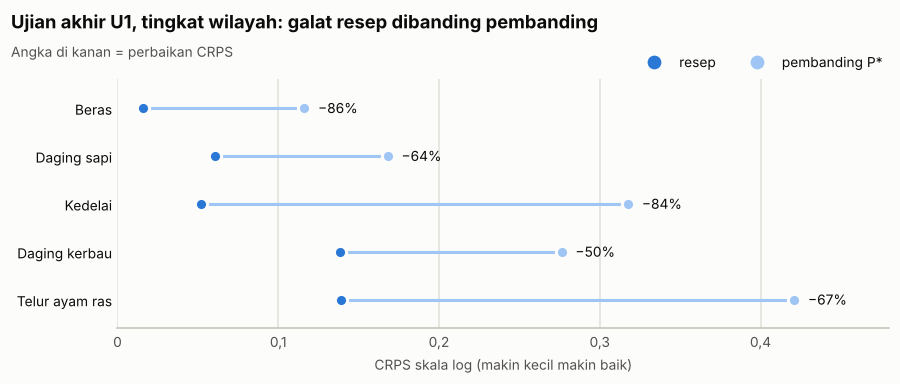

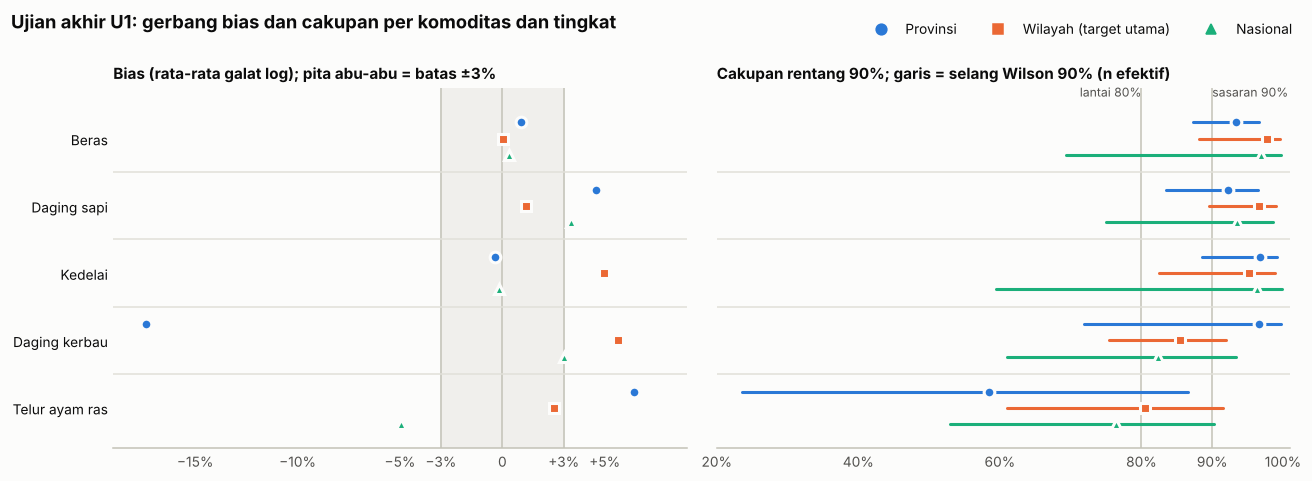

In [29]:
grafik_crps_u1()
grafik_gerbang_u1()

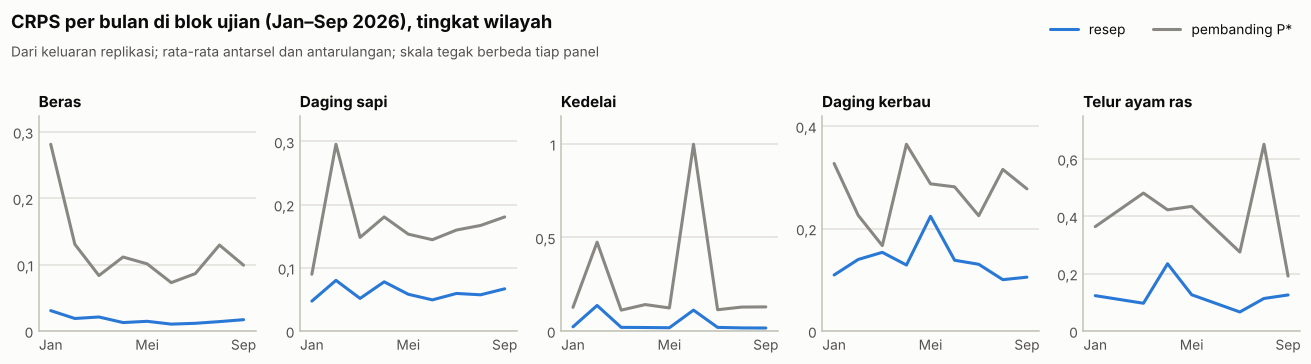

In [30]:
grafik_u1_bulanan()

## 5. Keterwakilan beras (U2) terhadap Pola Distribusi BPS
Pertanyaan: apakah jalur antarprovinsi di INATRADE (PAW beras, tanpa BULOG) cocok dengan daftar provinsi mitra di
publikasi BPS "Distribusi Perdagangan Komoditas Beras" edisi 2025? BPS hanya menerbitkan **daftar** mitra (bukan
pangsa), jadi gerbang diganti perbandingan jalur dan dikunci sebelum edisi 2025 dibuka (`RANCANGAN_U2.md` bagian 6):
- **Gerbang (i) "lebih dekat":** average precision gabungan (BPS 2024 + INATRADE) > INATRADE mentah **dan** > BPS 2024
  apa adanya, dengan selang 90% bootstrap dari selisihnya seluruhnya > 0.
- **Gerbang (ii) pengganti korelasi pangsa asal:** korelasi peringkat volume keluar INATRADE per provinsi asal vs jumlah
  provinsi yang menyebutnya asal di BPS 2025 ≥ 0,6.

Hasil resmi (14 Nov 2026, sekali jalan, sudah terpakai): gerbang (i) **LOLOS**, gerbang (ii) **GAGAL** → INATRADE
dilaporkan sebagai **penguat peta jalur BPS**, bukan gambaran pola asal perdagangan beras.

**Hasil U2 RESMI** (14 Nov 2026; sekali jalan, sudah terpakai):

,Average precision,Tautan,Presisi,Recall,F1
acak (kepadatan),"0,093",1122,9%,100%,"0,17"
INATRADE mentah,"0,329",77,51%,38%,"0,43"
BPS 2024 apa adanya,"0,480",150,57%,82%,"0,67"
gabungan (BPS 2024 + INATRADE),"0,563",185,50%,89%,"0,64"


Cakupan: 34 provinsi, 1122 pasangan berarah; tautan BPS 2024 150, BPS 2025 104, tetap 85; perusahaan PAW INATRADE 26, provinsi asal 9.
Gabungan − INATRADE mentah: +0,234 (selang 90% 0,167 … 0,300)
Gabungan − BPS 2024 apa adanya: +0,083 (selang 90% 0,041 … 0,133)
Korelasi peringkat volume keluar INATRADE vs BPS 2025: 0,20 (batas 0,6); versi jumlah tujuan 0,20; BPS 2024 vs BPS 2025 0,89
Gerbang (i) lebih dekat: LOLOS | gerbang (ii) korelasi asal: GAGAL


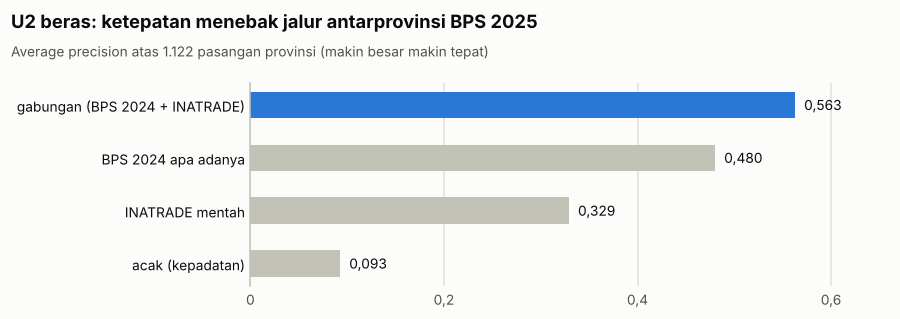

In [31]:
def tabel_u2(h):
    v = pd.DataFrame(h['versi']).T
    urut = ['acak (kepadatan)', 'INATRADE mentah', 'BPS 2024 apa adanya', 'gabungan (BPS 2024 + INATRADE)']
    v = v.reindex([u for u in urut if u in v.index])
    t = pd.DataFrame({'Average precision': v.ap.map(lambda x: idn(f'{x:.3f}')), 'Tautan': v.tautan.astype(int),
                      'Presisi': v.presisi.map(lambda x: f'{x:.0%}'), 'Recall': v.recall.map(lambda x: f'{x:.0%}'),
                      'F1': v.f1.map(lambda x: idn(f'{x:.2f}'))})
    s, k, g = h['selisih_gabungan'], h['korelasi'], h['gerbang']
    teks = [f"Cakupan: {h['provinsi']} provinsi, {h['pasangan']} pasangan berarah; tautan BPS 2024 {h['tautan_bps2024']}, "
            f"BPS 2025 {h['tautan_bps2025']}, tetap {h['tetap_2024_ke_2025']}; perusahaan PAW INATRADE {h['perusahaan_paw']}, "
            f"provinsi asal {k['provinsi_asal_inatrade']}."]
    for nm, d in s.items():
        teks.append(idn(f"Gabungan − {nm}: {d['selisih']:+.3f} (selang 90% {d['lo']:.3f} … {d['hi']:.3f})"))
    teks.append(idn(f"Korelasi peringkat volume keluar INATRADE vs BPS 2025: {k['volume_vs_bps2025']:.2f} (batas 0,6); "
                    f"versi jumlah tujuan {k['jumlah_tujuan_vs_bps2025']:.2f}; BPS 2024 vs BPS 2025 {k['bps2024_vs_bps2025']:.2f}"))
    teks.append(f"Gerbang (i) lebih dekat: {g['lebih_dekat'].upper()} | gerbang (ii) korelasi asal: {g['korelasi_asal'].upper()}")
    return t, teks


def ratakan(d, awalan=''):
    out = {}
    for k, v in d.items():
        if isinstance(v, dict):
            out.update(ratakan(v, f'{awalan}{k}/'))
        elif k not in ('mulai', 'selesai'):
            out[awalan + k] = v
    return out


U2_RESMI = json.load(open(R('hasil_u2_beras', 'hasil_U2.json')))
display(Markdown('**Hasil U2 RESMI** (14 Nov 2026; sekali jalan, sudah terpakai):'))
_t, _teks = tabel_u2(U2_RESMI)
display(_t)
print('\n'.join(_teks))
grafik_u2(U2_RESMI)

In [32]:
# REPLIKASI U2 (bukan ujian baru): skrip, daftar mitra BPS, dan file INATRADE yang sama, ke folder terpisah
if not DATA_SAMA:
    print('DILEWATI: file INATRADE berbeda dari file hasil resmi (data baru tidak dipakai mengulang ujian).')
else:
    _out = os.path.join(HASIL, 'replikasi_u2_beras')
    shutil.rmtree(_out, ignore_errors=True)
    os.makedirs(_out)
    print(f'REPLIKASI (bukan ujian baru) -> {_out}')
    if jalan('binpas/u2_beras.py', XLSM, R('data_publik', 'poldis_beras_2024_mitra.csv'),
             R('data_publik', 'poldis_beras_2025_mitra.csv'), _out, log=os.path.join(_out, 'layar_u2.txt')) == 0:
        _u = json.load(open(os.path.join(_out, 'hasil_U2.json')))
        _t, _teks = tabel_u2(_u)
        display(_t)
        print('\n'.join(_teks))
        _a, _b = ratakan(U2_RESMI), ratakan(_u)
        _maks, _sama = 0.0, set(_a) == set(_b)
        for _k in set(_a) & set(_b):
            if isinstance(_a[_k], (int, float)) and not isinstance(_a[_k], bool):
                _maks = max(_maks, abs(_b[_k] - _a[_k]) / max(abs(_a[_k]), 1e-12))
            else:
                _sama = _sama and _a[_k] == _b[_k]
        print(vonis(_maks, _sama))

REPLIKASI (bukan ujian baru) -> hasil_ulang/replikasi_u2_beras


{
 "provinsi": 34,
 "pasangan": 1122,
 "tautan_bps2025": 104,
 "tautan_bps2024": 150,
 "tetap_2024_ke_2025": 85,
 "perusahaan_paw": 26,
 "versi": {
  "INATRADE mentah": {
   "ap": 0.32906946330220993,
   "tautan": 77,
   "presisi": 0.5064935064935064,
   "recall": 0.375,
   "f1": 0.43093922651933697
  },
  "BPS 2024 apa adanya": {
   "ap": 0.48007507198683663,
   "tautan": 150,
   "presisi": 0.5666666666666667,
   "recall": 0.8173076923076923,
   "f1": 0.6692913385826771
  },
  "gabungan (BPS 2024 + INATRADE)": {
   "ap": 0.5627132869779928,
   "tautan": 185,
   "presisi": 0.5027027027027027,
   "recall": 0.8942307692307693,
   "f1": 0.643598615916955
  },
  "acak (kepadatan)": {
   "ap": 0.09269162210338681,
   "tautan": 1122,
   "presisi": 0.09269162210338681,
   "recall": 1.0,
   "f1": 0.1696574225122349
  }
 },
 "selisih_gabungan": {
  "INATRADE mentah": {
   "selisih": 0.2336438236757829,
   "lo": 0.16680399468415502,
   "hi": 0.3001710616712346
  },
  "BPS 2024 apa adanya": {
   

,Average precision,Tautan,Presisi,Recall,F1
acak (kepadatan),"0,093",1122,9%,100%,"0,17"
INATRADE mentah,"0,329",77,51%,38%,"0,43"
BPS 2024 apa adanya,"0,480",150,57%,82%,"0,67"
gabungan (BPS 2024 + INATRADE),"0,563",185,50%,89%,"0,64"


Cakupan: 34 provinsi, 1122 pasangan berarah; tautan BPS 2024 150, BPS 2025 104, tetap 85; perusahaan PAW INATRADE 26, provinsi asal 9.
Gabungan − INATRADE mentah: +0,234 (selang 90% 0,167 … 0,300)
Gabungan − BPS 2024 apa adanya: +0,083 (selang 90% 0,041 … 0,133)
Korelasi peringkat volume keluar INATRADE vs BPS 2025: 0,20 (batas 0,6); versi jumlah tujuan 0,20; BPS 2024 vs BPS 2025 0,89
Gerbang (i) lebih dekat: LOLOS | gerbang (ii) korelasi asal: GAGAL
SAMA PERSIS dengan hasil resmi (semua kolom angka identik)


## 6. Resep versi 2: kedelai, daging kerbau, telur ayam ras — DIKUNCI, BELUM DIUJI
Ketiga komoditas gagal U1 dengan resep versi 1. Sesuai aturan revisi (`RANCANGAN_V2.md`; disetujui Bu Fitria 14 Nov
2026), resep versi 2 disetel dengan prosedur yang sama pada **seluruh data yang sudah terlihat** (Jan 2024–Sep 2026) dan
dikunci sebelum data baru dilihat. Ambang tidak diubah.

**Tabel di bawah adalah hasil PENYETELAN (gerbang dinilai di Jan 2025–Sep 2026, termasuk periode ujian versi 1), BUKAN
hasil ujian.** Ujian yang sah hanya boleh memakai bulan-bulan **sesudah Sep 2026** (perkiraan butuh Okt 2026–Mar 2027,
±April 2027), sekali jalan, tanpa mengubah `resep.json`. Notebook ini sengaja **tidak menyediakan sel ujian versi 2**;
langkahnya ada di `RANCANGAN_V2.md` bagian 4 (unduh ulang INATRADE, perpanjang `tahap0.PER`, kalibrasi, lalu ujian).
Tambahan "luar" yang ikut tertulis di resep daging kerbau dan telur tidak berpengaruh (tidak ada peubah luar di luar beras).

In [33]:
for _label, _folder, _v1 in [('Kedelai', 'hasil_v2_kedelai', 'hasil_adu_kedelai'),
                             ('Daging kerbau', 'hasil_v2_daging_kerbau', 'hasil_adu_daging_kerbau'),
                             ('Telur ayam ras', 'hasil_v2_telur_ayam', 'hasil_adu_telur_ayam')]:
    _r2, _r1 = json.load(open(R(_folder, 'resep.json'))), json.load(open(R(_v1, 'resep.json')))
    display(Markdown(f'**{_label}** — resep versi 1 (gagal U1): {uraian_resep(_r1)}<br>'
                     f'**resep versi 2 (dikunci, belum diuji):** {uraian_resep(_r2)}'))
    display(tabel_gerbang(baca_gerbang(R(_folder, 'gerbang_penyetelan.csv'))))

**Kedelai** — resep versi 1 (gagal U1): identitas I0; isian B (semua lubang diisi); tambahan tdist; bobot pelapor tanpa; ragam 1,0×; rekonsiliasi tanpa; koreksi akhir konformal; pembanding P* = A3<br>**resep versi 2 (dikunci, belum diuji):** identitas I0; isian C (semua lubang diisi); tambahan tdist; bobot pelapor tanpa; ragam 1,0×; rekonsiliasi tanpa; koreksi akhir tanpa; pembanding P* = A3

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,107,89,41
CRPS log (resep / P*),"0,043 / 0,259","0,051 / 0,203","0,015 / 0,088"
Perbaikan CRPS,84%,75%,83%
MAE median (resep / P*),"0,058 / 0,325","0,069 / 0,237","0,020 / 0,110"
"Selisih CRPS, rentang 90% bootstrap","-0,248 … -0,187","-0,244 … -0,083","-0,079 … -0,068"
Bias (resep / P*),"0,0% / -12,6%","+2,5% / -10,6%","+0,3% / -1,5%"
Arah perubahan sama,94%,97%,95%
Cakupan rentang 90%,"88,7%","83,4%","89,8%"
Selang Wilson 90% (n efektif),"80,3%–93,7% (61)","72,4%–90,6% (44)","66,0%–97,6% (11)"
Status,lolos semua gerbang,lolos semua gerbang,lolos; cakupan belum bisa diputuskan


**Daging kerbau** — resep versi 1 (gagal U1): identitas I0; isian R4 (semua lubang diisi); tambahan ciri + luar + pola; bobot pelapor tanpa; ragam 0,5×; rekonsiliasi tanpa; koreksi akhir tanpa; pembanding P* = A5<br>**resep versi 2 (dikunci, belum diuji):** identitas I0; isian B (semua lubang diisi); tambahan luar + tdist; bobot pelapor tanpa; ragam 0,5×; rekonsiliasi tanpa; koreksi akhir tanpa; pembanding P* = A5

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,9,113,41
CRPS log (resep / P*),"0,121 / 0,683","0,093 / 0,283","0,060 / 0,125"
Perbaikan CRPS,82%,67%,52%
MAE median (resep / P*),"0,152 / 0,702","0,121 / 0,344","0,081 / 0,156"
"Selisih CRPS, rentang 90% bootstrap","-0,798 … -0,302","-0,239 … -0,150","-0,079 … -0,051"
Bias (resep / P*),"-0,7% / -24,1%","+0,9% / -12,0%","+1,2% / -3,3%"
Arah perubahan sama,73%,87%,93%
Cakupan rentang 90%,"94,7%","85,2%","81,3%"
Selang Wilson 90% (n efektif),"63,5%–99,5% (6)","75,3%–91,6% (51)","60,7%–92,5% (15)"
Status,gagal (arah),lolos semua gerbang,lolos; cakupan belum bisa diputuskan


**Telur ayam ras** — resep versi 1 (gagal U1): identitas I1; isian B (semua lubang diisi); tambahan tdist; bobot pelapor tanpa; ragam 1,0×; rekonsiliasi tanpa; koreksi akhir tanpa; pembanding P* = A3<br>**resep versi 2 (dikunci, belum diuji):** identitas I0; isian R1 (semua lubang diisi); tambahan luar; bobot pelapor tanpa; ragam 1,0×; rekonsiliasi tanpa; koreksi akhir tanpa; pembanding P* = A3

,Provinsi,Wilayah (target utama),Nasional
Sel-bulan,16,45,41
CRPS log (resep / P*),"0,100 / 0,644","0,060 / 0,376","0,078 / 0,284"
Perbaikan CRPS,84%,84%,72%
MAE median (resep / P*),"0,126 / 0,693","0,082 / 0,447","0,097 / 0,344"
"Selisih CRPS, rentang 90% bootstrap","-0,697 … -0,383","-0,353 … -0,281","-0,242 … -0,174"
Bias (resep / P*),"-0,3% / -26,8%","+0,3% / -18,0%","-5,1% / -10,7%"
Arah perubahan sama,85%,92%,93%
Cakupan rentang 90%,"79,9%","87,2%","80,1%"
Selang Wilson 90% (n efektif),"59,7%–91,4% (16)","76,1%–93,6% (40)","65,9%–89,3% (30)"
Status,gagal (cakupan),lolos semua gerbang,"gagal (bias, cakupan)"


In [34]:
# Log proses RESMI resep versi 2 (penyetelan Jan 2024-Sep 2026; BUKAN ujian). Judul "Jan-Jun 2025" di dalam log adalah
# teks bawaan skrip; untuk versi 2 gerbang dinilai di Jan 2025-Sep 2026.
for _label, _folder in [('KEDELAI', 'hasil_v2_kedelai'), ('DAGING KERBAU', 'hasil_v2_daging_kerbau'), ('TELUR AYAM RAS', 'hasil_v2_telur_ayam')]:
    tampil_log(_folder, 'log_penyetelan.txt', f'{_label} versi 2 - log penyetelan resmi')
    tampil_log(_folder, 'log_turun_peringkat.txt', f'{_label} versi 2 - log turun peringkat resmi')

KEDELAI versi 2 - log penyetelan resmi  [paket/binpas/hasil_v2_kedelai/log_penyetelan.txt]
== penyetelan 2026-11-14 15:32:13 | KEDELAI BAHAN BAKU TEMPE DAN TAHU | perusahaan 73, besar 12, wilayah [42, 24, 7] | pola hapus: h=[0.112 0.068], p_ekor=[0.405 0.133] | proses 4
[1a identitas] 3 versi, 500 ulangan, 29 detik
cfg
I0|R2|99||3|1.0|0    0.0823
I2|R2|99||3|1.0|0    0.0859
I1|R2|99||3|1.0|0    0.0871
-> identitas: I0; pembanding P* = A3
[1b isian] 24 versi, 500 ulangan, 52 detik
cfg
I0|C|99||3|1.0|0     0.0437
I0|B|99||3|1.0|0     0.0441
I0|C|6||3|1.0|0      0.0529
I0|B|6||3|1.0|0      0.0533
I0|C|3||3|1.0|0      0.0570
I0|B|3||3|1.0|0      0.0575
I0|C|2||3|1.0|0      0.0641
I0|B|2||3|1.0|0      0.0642
I0|R4|99||3|1.0|0    0.0685
I0|R2|99||3|1.0|0    0.0692
I0|R3|99||3|1.0|0    0.0698
I0|R1|99||3|1.0|0    0.0715
I0|R4|6||3|1.0|0     0.0772
I0|R2|6||3|1.0|0     0.0778
I0|R3|6||3|1.0|0     0.0785
I0|R1|6||3|1.0|0     0.0797
I0|R4|3||3|1.0|0     0.0805
I0|R2|3||3|1.0|0     0.0813
I0|R3|3

## 7. Ringkasan status tujuh komoditas
Kolom Provinsi / Wilayah / Nasional dihitung dari `gerbang_U1.csv` resmi (termasuk gerbang "memburuk ≤ 20%" terhadap
resep yang sama di blok penyetelan). Kolom terakhir = status yang dilaporkan sesudah keputusan Bu Fitria (14 Nov 2026).
Tangga klaim: yang dilaporkan adalah tingkat terhalus yang lolos; target utama = wilayah.

In [35]:
KEPUTUSAN = {
    'BERAS': 'wilayah LOLOS U1; provinsi lolos dengan catatan (+13% / +28% menurut acuan); nasional cakupan belum bisa diputuskan',
    'DAGING SAPI': 'wilayah LOLOS U1 (satuan dikoreksi; resep hasil turun peringkat); provinsi dan nasional gagal bias',
    'KEDELAI BAHAN BAKU TEMPE DAN TAHU': 'wilayah gagal U1 (bias) -> "tercatat"; provinsi lolos U1, dilaporkan dengan catatan; resep versi 2 menunggu data baru',
    'DAGING KERBAU': 'gagal U1 (bias) -> "tercatat"; resep versi 2 menunggu data baru',
    'TELUR AYAM RAS': 'gagal U1 (memburuk > 20%) -> "tercatat"; resep versi 2 menunggu data baru'}
_baris = []
for _label, _kom, _folder in UJI:
    _g, _ac = baca_gerbang(R(_folder, 'gerbang_U1.csv')), acuan_penyetelan(_folder)
    _baris.append({'Komoditas': _label, **{NAMA_TK[tk]: status(_g.loc[tk], _ac.loc[tk]) for tk in TK},
                   'Status akhir (14 Nov 2026)': KEPUTUSAN[_kom]})
_baris.append({'Komoditas': 'Pupuk', 'Provinsi': 'tidak diuji', NAMA_TK['wil']: 'tidak diuji', 'Nasional': 'tidak diuji',
               'Status akhir (14 Nov 2026)': '"tercatat" (gagal bias di penyetelan; pelapor tinggal 4)'})
_baris.append({'Komoditas': 'Daging ayam ras', 'Provinsi': 'tidak diuji', NAMA_TK['wil']: 'tidak diuji', 'Nasional': 'tidak diuji',
               'Status akhir (14 Nov 2026)': '"tercatat" (tidak bisa diuji; tidak ada data 2024)'})
display(pd.DataFrame(_baris).set_index('Komoditas'))
print('Keterwakilan beras (U2): gerbang "lebih dekat"', U2_RESMI['gerbang']['lebih_dekat'].upper(),
      '| gerbang korelasi asal', U2_RESMI['gerbang']['korelasi_asal'].upper(),
      '-> INATRADE = penguat peta jalur BPS, bukan gambaran pola asal.')
print('Arti "lolos": resep menutup laporan yang bolong secara konsisten; BUKAN bukti mewakili pasar (cakupan volume: bagian 3).')

,Provinsi,Wilayah (target utama),Nasional,Status akhir (14 Nov 2026)
Komoditas,,,,
Beras,lolos semua gerbang,lolos semua gerbang,lolos; cakupan belum bisa diputuskan,wilayah LOLOS U1; provinsi lolos dengan catatan (+13% / +28% menurut acuan); nasional cakupan belum bisa diputuskan
Daging sapi (satuan terkoreksi),gagal (bias),lolos semua gerbang,gagal (bias),wilayah LOLOS U1 (satuan dikoreksi; resep hasil turun peringkat); provinsi dan nasional gagal bias
Kedelai,lolos semua gerbang,gagal (bias),lolos; cakupan belum bisa diputuskan,"wilayah gagal U1 (bias) -> ""tercatat""; provinsi lolos U1, dilaporkan dengan catatan; resep versi 2 menunggu data baru"
Daging kerbau,"gagal (bias, arah)",gagal (bias),"gagal (bias, memburuk > 20%)","gagal U1 (bias) -> ""tercatat""; resep versi 2 menunggu data baru"
Telur ayam ras,"gagal (bias, cakupan, memburuk > 20%)",gagal (memburuk > 20%),"gagal (bias, cakupan, memburuk > 20%)","gagal U1 (memburuk > 20%) -> ""tercatat""; resep versi 2 menunggu data baru"
Pupuk,tidak diuji,tidak diuji,tidak diuji,"""tercatat"" (gagal bias di penyetelan; pelapor tinggal 4)"
Daging ayam ras,tidak diuji,tidak diuji,tidak diuji,"""tercatat"" (tidak bisa diuji; tidak ada data 2024)"


Keterwakilan beras (U2): gerbang "lebih dekat" LOLOS | gerbang korelasi asal GAGAL -> INATRADE = penguat peta jalur BPS, bukan gambaran pola asal.
Arti "lolos": resep menutup laporan yang bolong secara konsisten; BUKAN bukti mewakili pasar (cakupan volume: bagian 3).


## 8. (Opsional, mati) Penyetelan ulang penuh
Tidak diperlukan untuk membaca hasil. Isi `ULANG_PENYETELAN` dengan nama komoditas persis bila ingin mengulang adu versi
di blok penyetelan dari nol ke `hasil_ulang/penyetelan_<komoditas>/` (blok kalibrasi dan ujian tidak disentuh):
- komoditas selain beras: ±3 menit, ditambah turun peringkat ±3–7 menit bila pemenang gagal gerbang wilayah;
- **beras: ±1,3 jam** (4 CPU; di Colab bisa 2–3 jam) dan butuh `catboost`, `quantile-forest`, `statsmodels`. Hasilnya
  tidak akan persis sama dengan penyetelan resmi (seed isian resmi tidak bisa diulang; lihat 4.1). Jalur ini **belum
  pernah dicoba di Colab**.

Nama persis: `BERAS`, `DAGING SAPI`, `DAGING KERBAU`, `DAGING AYAM RAS`, `TELUR AYAM RAS`,
`KEDELAI BAHAN BAKU TEMPE DAN TAHU`, `PUPUK`. Penyetelan ulang tidak mengubah resep resmi dan tidak boleh dipakai untuk
mengganti resep yang sudah diuji.

In [36]:
ULANG_PENYETELAN = []        # mis. ['KEDELAI BAHAN BAKU TEMPE DAN TAHU']; kosong = tidak ada yang dijalankan

for _kom in ULANG_PENYETELAN:
    _out = os.path.join(HASIL, 'penyetelan_' + _kom.lower().replace(' ', '_'))
    if _kom == 'BERAS':
        _sasaran = ['--target', PUSTAKA, '--upgrade', 'pandas==3.0.5', 'openpyxl'] if PUSTAKA else []
        subprocess.run([PY, '-m', 'pip', 'install', '-q', *_sasaran, 'catboost', 'quantile-forest', 'statsmodels'], check=True)
    if jalan('binpas/adu_versi.py', 'penyetelan', XLSM, _out, BPS_OUT if _kom == 'BERAS' and os.path.isdir(BPS_OUT) else '-',
             *([] if _kom == 'BERAS' else [_kom])) != 0:
        continue
    _resep = json.load(open(os.path.join(_out, 'resep.json')))
    if _kom != 'BERAS' and not _resep.get('lolos_penyetelan', True):
        jalan('binpas/turun_peringkat.py', _out)
if not ULANG_PENYETELAN:
    print('tidak ada penyetelan ulang (ULANG_PENYETELAN kosong).')

tidak ada penyetelan ulang (ULANG_PENYETELAN kosong).
